# Imports

In [ ]:
import pandas as pd
import duckdb
import psycopg2
from getpass import getpass

import base64

import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np

In [ ]:
duckdb.sql("INSTALL httpfs")
duckdb.sql("LOAD httpfs")
duckdb.sql("INSTALL postgres")
duckdb.sql("LOAD postgres")

## Credentials

In [ ]:
username = "kalshidatabase"
password = "KalshiData2026!"

In [ ]:
# Authentication
token = base64.b64encode(
    f"{username}:{password}".encode()
).decode()

duckdb.sql(f"""
    CREATE OR REPLACE SECRET kalshi_access (
        TYPE http,
        SCOPE 'https://d389h2c6tmngyk.cloudfront.net/',
        EXTRA_HTTP_HEADERS MAP {{
            'Authorization': 'Basic {token}'
        }}
    )
""")

┌─────────┐
│ Success │
│ boolean │
├─────────┤
│ true    │
└─────────┘

In [ ]:
file_url = (
    "https://d389h2c6tmngyk.cloudfront.net/"
    "events-2026-10-09T23.parquet"
)

# Step 1 — Inspect the orderbook Parquet file
Review the schema, a small preview, and full row count. full_df loads the complete example file.

In [ ]:
# Column Information
schema_df = duckdb.sql(f"""
    DESCRIBE SELECT *
    FROM read_parquet('{file_url}')
""").df()

schema_df

,column_name,column_type,null,key,default,extra
0,ts_ms,BIGINT,YES,None,None,None
1,asset_id,VARCHAR,YES,None,None,None
2,market,VARCHAR,YES,None,None,None
3,side,VARCHAR,YES,None,None,None
4,price,DOUBLE,YES,None,None,None
5,size,DOUBLE,YES,None,None,None


In [ ]:
# Sample Dataframe
sample_df = duckdb.sql(f"""
    SELECT *
    FROM read_parquet('{file_url}')
    LIMIT 5
""").df()

sample_df

,ts_ms,asset_id,market,side,price,size
0,1791589563481,EVSHARE-30JAN-30,92fb2641-61bc-4dc0-8f3a-35f440ab149c,BUY,0.41,2.60
1,1791589565419,EVSHARE-30JAN-30,92fb2641-61bc-4dc0-8f3a-35f440ab149c,SELL,0.89,0.00
2,1791589565420,EVSHARE-30JAN-30,92fb2641-61bc-4dc0-8f3a-35f440ab149c,SELL,0.90,2.01
3,1791589598438,EVSHARE-30JAN-30,92fb2641-61bc-4dc0-8f3a-35f440ab149c,BUY,0.41,67.60
4,1791589779889,EVSHARE-30JAN-30,92fb2641-61bc-4dc0-8f3a-35f440ab149c,SELL,0.80,0.00


In [ ]:
row_count = duckdb.sql(f"""
    select count(*) as total_rows
    from read_parquet('{file_url}')
""").df()

row_count
# 629K rows

,total_rows
0,628513


# Step 2 — Inspect the PostgreSQL tables
The connection is read-only. The SQL below previews table structure and example records.

In [ ]:
con = psycopg2.connect(
    host='kalshi-research-database-mzisps9yykpj.cpch6mrqzcov.us-west-2.rds.amazonaws.com',
    port=5432,
    dbname="kalshi",
    user='kalshidatabase',
    password=password,
    sslmode="require",
    connect_timeout=60,
)

# Read data without leaving read transactions open.
con.set_session(readonly=True, autocommit=True)

In [ ]:
with con.cursor() as cur:
    cur.execute("""
        SELECT table_schema, table_name
        FROM information_schema.tables
        WHERE table_type = 'BASE TABLE'
          AND table_schema = 'public'
        ORDER BY table_schema, table_name
    """)

    tables_df = pd.DataFrame(
        cur.fetchall(),
        columns=["table_schema", "table_name"],
    )

tables_df

,table_schema,table_name
0,public,events
1,public,hourly_candles
2,public,markets


In [ ]:
with con.cursor() as cur:
    cur.execute("""
        SELECT table_name, column_name, data_type
        FROM information_schema.columns
        WHERE table_schema = 'public'
        ORDER BY table_name, ordinal_position
    """)

    columns_df = pd.DataFrame(
        cur.fetchall(),
        columns=["table_name", "column_name", "data_type"],
    )

columns_df

,table_name,column_name,data_type
0,events,slug,text
1,events,title,text
2,events,ticker,text
3,events,start_date,timestamp with time zone
4,events,end_date,timestamp with time zone
...,...,...,...
58,markets,volume_unit,text
59,markets,source_updated_at,timestamp with time zone
60,markets,observed_at,timestamp with time zone
61,markets,raw_payload,jsonb


In [ ]:
# Markets Table
with con.cursor() as cur:
    cur.execute("""
        SELECT slug, ticker, title, event_slug,
               last_trade_price, best_bid, best_ask
        FROM public.markets
        where 1=1
            and last_trade_price > 0
            and best_bid > 0
            and best_ask > 0
        LIMIT 5
    """)
    markets_df = pd.DataFrame(
        cur.fetchall(),
        columns=[column.name for column in cur.description],
    )

markets_df

,slug,ticker,title,event_slug,last_trade_price,best_bid,best_ask
0,KXETH-25APR1409-B1670,KXETH-25APR1409-B1670,"Ethereum price at Apr 14, 2025 at 9am EDT?",KXETH-25APR1409,0.7000,0.7600,1.0000
1,KXETH-25APR1317-B1610,KXETH-25APR1317-B1610,"Ethereum price at Apr 13, 2025 at 5pm EDT?",KXETH-25APR1317,0.7700,0.5300,1.0000
2,KXETH-25APR1323-B1640,KXETH-25APR1323-B1640,"Ethereum price at Apr 13, 2025 at 11pm EDT?",KXETH-25APR1323,0.9700,0.7000,0.9900
3,KXETH-25APR1322-B1620,KXETH-25APR1322-B1620,"Ethereum price at Apr 13, 2025 at 10pm EDT?",KXETH-25APR1322,0.9800,0.9900,1.0000
4,KXETH-25APR1321-B1620,KXETH-25APR1321-B1620,"Ethereum price at Apr 13, 2025 at 9pm EDT?",KXETH-25APR1321,0.9800,0.5500,1.0000


In [ ]:
# Events Table
with con.cursor() as cur:
    cur.execute("""
        SELECT slug, ticker, title, category,
               start_date, end_date, active, closed
        FROM public.events
        LIMIT 5
    """)
    events_df = pd.DataFrame(
        cur.fetchall(),
        columns=[column.name for column in cur.description],
    )

events_df


,slug,ticker,title,category,start_date,end_date,active,closed
0,KXMVECROSSCATEGORY-SHARD1-S20266811E4DCCAA,KXMVECROSSCATEGORY-SHARD1-S20266811E4DCCAA,Arsenal vs Coventry,Exotics,None,None,None,None
1,KXMVECROSSCATEGORY-SHARD1-S20266830361056B,KXMVECROSSCATEGORY-SHARD1-S20266830361056B,Espanyol vs Real Madrid,Exotics,None,None,None,None
2,KXMVECROSSCATEGORY-SHARD1-S202668D9FF1956F,KXMVECROSSCATEGORY-SHARD1-S202668D9FF1956F,Arsenal vs Coventry,Exotics,None,None,None,None
3,KXMVECROSSCATEGORY-SHARD1-S202668DFDD11684,KXMVECROSSCATEGORY-SHARD1-S202668DFDD11684,Arsenal vs Coventry,Exotics,None,None,None,None
4,KXMVECROSSCATEGORY-SHARD1-S20266963652C7C7,KXMVECROSSCATEGORY-SHARD1-S20266963652C7C7,Arsenal vs Coventry,Exotics,None,None,None,None


In [ ]:
# Hourly Candles Table
with con.cursor() as cur:
    cur.execute("""
        SELECT market_slug, interval_minutes, end_time,
               yes_bid_open, yes_bid_high, yes_bid_low, yes_bid_close,
               yes_ask_open, yes_ask_high, yes_ask_low, yes_ask_close,
               price_open, price_high, price_low, price_close,
               volume, open_interest
        FROM public.hourly_candles
        LIMIT 5
    """)
    hourly_candles_df = pd.DataFrame(
        cur.fetchall(),
        columns=[column.name for column in cur.description],
    )

hourly_candles_df
# 7.5M rows

,market_slug,interval_minutes,end_time,yes_bid_open,yes_bid_high,yes_bid_low,yes_bid_close,yes_ask_open,yes_ask_high,yes_ask_low,yes_ask_close,price_open,price_high,price_low,price_close,volume,open_interest
0,KXGOOG-26NOVHEAD-203000,60,2026-10-09 02:00:00+00:00,0.7600,0.7600,0.7500,0.7500,0.8400,0.8500,0.8400,0.8400,0.7600,0.7600,0.7500,0.7500,2.11,632.35
1,KXGOLDW-26OCT0917-T4521.99,60,2026-10-09 02:00:00+00:00,0.0000,0.0000,0.0000,0.0000,0.0100,0.0100,0.0100,0.0100,None,None,None,None,0.00,0.00
2,KXGOLDW-26OCT0917-T4541.99,60,2026-10-09 02:00:00+00:00,0.0000,0.0000,0.0000,0.0000,0.0100,0.0100,0.0100,0.0100,None,None,None,None,0.00,0.00
3,KXGOLDW-26OCT0917-T4401.99,60,2026-10-09 02:00:00+00:00,0.0000,0.0000,0.0000,0.0000,0.0100,0.0100,0.0100,0.0100,None,None,None,None,0.00,108.55
4,KXGOLDW-26OCT0917-T4441.99,60,2026-10-09 02:00:00+00:00,0.0000,0.0000,0.0000,0.0000,0.0100,0.0100,0.0100,0.0100,None,None,None,None,0.00,0.00


# Step 3 — Match orderbook rows to market and event metadata

In [ ]:
# Full Parquet dataset
full_df = duckdb.sql(f"""
    SELECT *
    FROM read_parquet('{file_url}')
""").df()

print(f"Rows: {len(full_df):,}")
print(
    f"Memory: "
    f"{full_df.memory_usage(deep=True).sum() / 1024**2:,.1f} MB"
)

full_df.head(10)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Rows: 628,513
Memory: 143.3 MB


,ts_ms,asset_id,market,side,price,size
0,1791589563481,EVSHARE-30JAN-30,92fb2641-61bc-4dc0-8f3a-35f440ab149c,BUY,0.41,2.60
1,1791589565419,EVSHARE-30JAN-30,92fb2641-61bc-4dc0-8f3a-35f440ab149c,SELL,0.89,0.00
2,1791589565420,EVSHARE-30JAN-30,92fb2641-61bc-4dc0-8f3a-35f440ab149c,SELL,0.90,2.01
3,1791589598438,EVSHARE-30JAN-30,92fb2641-61bc-4dc0-8f3a-35f440ab149c,BUY,0.41,67.60
4,1791589779889,EVSHARE-30JAN-30,92fb2641-61bc-4dc0-8f3a-35f440ab149c,SELL,0.80,0.00
5,1791589779899,EVSHARE-30JAN-30,92fb2641-61bc-4dc0-8f3a-35f440ab149c,BUY,0.20,0.00
6,1791589779914,EVSHARE-30JAN-30,92fb2641-61bc-4dc0-8f3a-35f440ab149c,SELL,0.89,48.00
7,1791589779914,EVSHARE-30JAN-30,92fb2641-61bc-4dc0-8f3a-35f440ab149c,SELL,0.90,48.01
8,1791589779932,EVSHARE-30JAN-30,92fb2641-61bc-4dc0-8f3a-35f440ab149c,BUY,0.18,1276.00
9,1791589779943,EVSHARE-30JAN-30,92fb2641-61bc-4dc0-8f3a-35f440ab149c,SELL,0.80,401.00


In [ ]:
# Get distinct market tickers from all Parquet rows.
tickers = full_df["asset_id"].dropna().unique().tolist()
print(f"Distinct tickers in Parquet: {len(tickers):,}")

Distinct tickers in Parquet: 2,056


In [ ]:
# Fetch only matching market and event metadata from PostgreSQL.
with con.cursor() as cur:
    cur.execute("""
        SELECT
            m.ticker,
            m.slug AS market_slug,
            m.title AS market_title,
            m.event_slug,
            e.title AS event_title,
            e.category AS event_category
        FROM public.markets AS m
        LEFT JOIN public.events AS e
            ON m.event_slug = e.slug
        WHERE m.ticker = ANY(%s)
    """, (tickers,))

    metadata_df = pd.DataFrame(
        cur.fetchall(),
        columns=[column.name for column in cur.description],
    )

print(f"Matching database tickers: {metadata_df['ticker'].nunique():,}")

Matching database tickers: 2,056


In [ ]:
# Add metadata to every Parquet row.
joined_df = full_df.merge(
    metadata_df,
    how="left",
    left_on="asset_id",
    right_on="ticker",
    validate="many_to_one",
    indicator=True,
)

print(f"Parquet rows: {len(full_df):,}")
print(f"Joined rows:  {len(joined_df):,}")
print(joined_df["_merge"].value_counts())

analysis_df = joined_df.drop(columns=["ticker", "market_slug"])
analysis_df.head()

Parquet rows: 628,513
Joined rows:  628,513
_merge
both          628513
left_only          0
right_only         0
Name: count, dtype: int64


,ts_ms,asset_id,market,side,price,size,market_title,event_slug,event_title,event_category,_merge
0,1791589563481,EVSHARE-30JAN-30,92fb2641-61bc-4dc0-8f3a-35f440ab149c,BUY,0.41,2.60,EV market share in 2030?,EVSHARE-30JAN,EV market share in 2030?,Climate and Weather,both
1,1791589565419,EVSHARE-30JAN-30,92fb2641-61bc-4dc0-8f3a-35f440ab149c,SELL,0.89,0.00,EV market share in 2030?,EVSHARE-30JAN,EV market share in 2030?,Climate and Weather,both
2,1791589565420,EVSHARE-30JAN-30,92fb2641-61bc-4dc0-8f3a-35f440ab149c,SELL,0.90,2.01,EV market share in 2030?,EVSHARE-30JAN,EV market share in 2030?,Climate and Weather,both
3,1791589598438,EVSHARE-30JAN-30,92fb2641-61bc-4dc0-8f3a-35f440ab149c,BUY,0.41,67.60,EV market share in 2030?,EVSHARE-30JAN,EV market share in 2030?,Climate and Weather,both
4,1791589779889,EVSHARE-30JAN-30,92fb2641-61bc-4dc0-8f3a-35f440ab149c,SELL,0.80,0.00,EV market share in 2030?,EVSHARE-30JAN,EV market share in 2030?,Climate and Weather,both


In [ ]:
market_slugs = joined_df["market_slug"].dropna().unique().tolist()

with con.cursor() as cur:
    cur.execute("""
        SELECT DISTINCT ON (market_slug, end_time)
            market_slug,
            end_time AS candle_end_time,
            observed_at,
            yes_bid_close,
            yes_ask_close,
            price_close,
            volume,
            open_interest
        FROM public.hourly_candles
        WHERE market_slug = ANY(%s)
          AND interval_minutes = 60
        ORDER BY market_slug, end_time, observed_at DESC
    """, (market_slugs,))

    candles_df = pd.DataFrame(
        cur.fetchall(),
        columns=[column.name for column in cur.description],
    )

print(f"Hourly candles fetched: {len(candles_df):,}")
candles_df.head()

In [ ]:
orderbook = joined_df.copy()
orderbook["orderbook_time"] = pd.to_datetime(
    orderbook["ts_ms"], unit="ms", utc=True
)

orderbook = orderbook.dropna(subset=["market_slug"])
candles_df["candle_end_time"] = pd.to_datetime(
    candles_df["candle_end_time"], utc=True
)

orderbook = orderbook.sort_values("orderbook_time")
candles_df = candles_df.sort_values("candle_end_time")

orderbook_with_candles = pd.merge_asof(
    orderbook,
    candles_df,
    by="market_slug",
    left_on="orderbook_time",
    right_on="candle_end_time",
    direction="backward",
)

print(f"Orderbook rows: {len(orderbook):,}")
print(
    "Rows with a prior hourly candle:",
    f"{orderbook_with_candles['candle_end_time'].notna().sum():,}"
)

orderbook_with_candles.head()

NameError: name 'candles_df' is not defined

# Step 4 — Check row coverage and data quality
Check that metadata and candle steps did not multiply orderbook rows. Summarize missing values and exact duplicate source records.

In [ ]:
coverage_summary = pd.DataFrame(
    {"measure": ["orderbook rows", "joined rows", "distinct asset IDs", "matched rows", "unmatched rows"],
     "value": [len(full_df), len(joined_df),
               full_df["asset_id"].nunique(dropna=True),
               int((joined_df["_merge"] == "both").sum()),
               int((joined_df["_merge"] == "left_only").sum())]
     })

display(coverage_summary)

missing_summary = pd.DataFrame(
    {"missing_rows": joined_df.isna().sum(),
     "missing_pct": (100 * joined_df.isna().mean()).round(2)
     }
    ).sort_values("missing_rows", ascending=False)

print("Exact duplicate source rows:", int(full_df.duplicated().sum()))
display(missing_summary)

,measure,value
0,orderbook rows,628513
1,joined rows,628513
2,distinct asset IDs,2056
3,matched rows,628513
4,unmatched rows,0


Exact duplicate source rows: 0


,missing_rows,missing_pct
ts_ms,0,0.0
asset_id,0,0.0
market,0,0.0
side,0,0.0
price,0,0.0
size,0,0.0
ticker,0,0.0
market_slug,0,0.0
market_title,0,0.0
event_slug,0,0.0


# Step 5 — Understand the timestamps
ts_ms is milliseconds since the Unix epoch. Convert it to UTC, inspect the period covered, and count orderbook records per day.

In [ ]:
eda_df = joined_df.copy()
eda_df["orderbook_time"] = pd.to_datetime(
    eda_df["ts_ms"], unit="ms", utc=True
)

print("First orderbook timestamp:", eda_df["orderbook_time"].min())
print("Last orderbook timestamp: ", eda_df["orderbook_time"].max())
print("Distinct UTC days:         ", eda_df["orderbook_time"].dt.floor("D").nunique())

First orderbook timestamp: 2026-10-09 23:00:00.012000+00:00
Last orderbook timestamp:  2026-10-09 23:59:59.992000+00:00
Distinct UTC days:          1


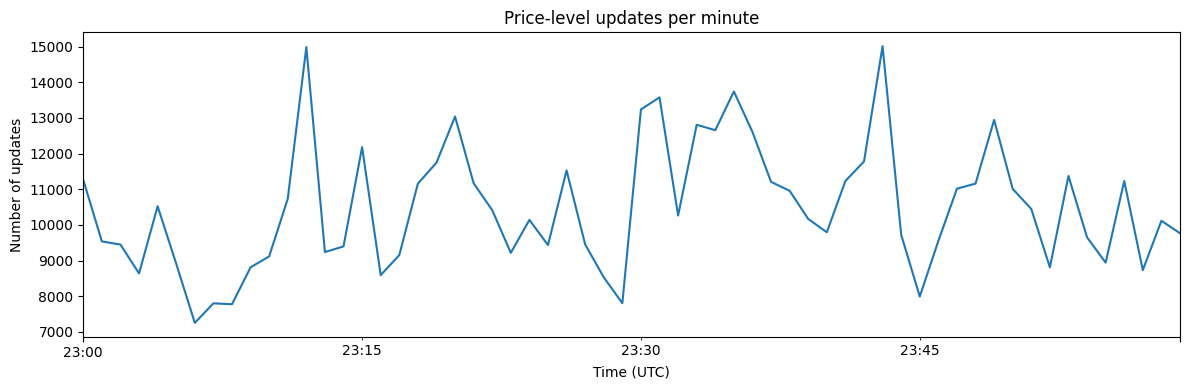

In [ ]:
# Price-level updates per minute on October 9, 2026 (23:00–23:59 UTC)
minute_updates = (
    eda_df.set_index("orderbook_time")
    .resample("min")
    .size()
    .rename("price_level_updates")
)

minute_updates.plot(
    figsize=(12, 4),
    title="Price-level updates per minute",
    xlabel="Time (UTC)",
    ylabel="Number of updates",
)

plt.tight_layout()
plt.show()

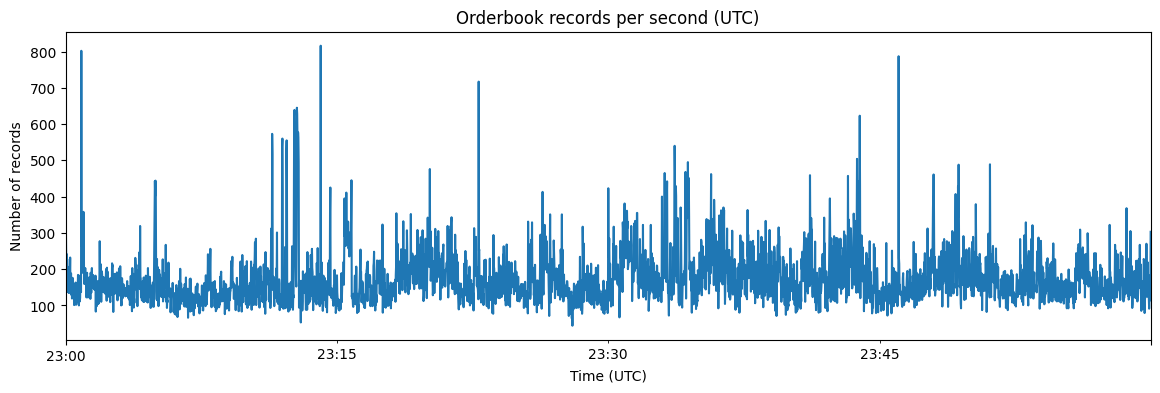

In [ ]:
# Number of Orderbook records per second from October 9th, 2026 between 23:00 to 23:59
second_counts = (
    eda_df.set_index("orderbook_time")
    .resample("s")
    .size()
    .rename("orderbook_rows")
)

second_counts.plot(
    figsize=(14, 4),
    title="Orderbook records per second (UTC)",
    xlabel="Time (UTC)",
    ylabel="Number of records",
);

# Step 6 — See which markets and events dominate
These are orderbook record counts, not counts of executed trades.

In [ ]:
market_activity = eda_df.groupby(["asset_id", "market_title", "event_slug"], dropna=False).size().rename("orderbook_rows").sort_values(ascending=False).to_frame()
event_activity = eda_df.groupby(["event_slug", "event_title", "event_category"], dropna=False).size().rename("orderbook_rows").sort_values(ascending=False).to_frame()

print("Markets represented:", eda_df["asset_id"].nunique(dropna=True))
print("Events represented: ", eda_df["event_slug"].nunique(dropna=True))

Markets represented: 2056
Events represented:  1601


In [ ]:
display(market_activity.head(15))

,,,orderbook_rows
asset_id,market_title,event_slug,
KXWNBATEAMTOTAL-26OCT09ATLNY-NY77,New York over 76.5 points scored,KXWNBATEAMTOTAL-26OCT09ATLNY,31578
KXWNBASPREAD-26OCT09ATLNY-NY4,New York wins the game by over 3.5 points,KXWNBASPREAD-26OCT09ATLNY,17390
KXLIGAEXPSPREAD-26OCT09TAPCLU-CLU3,Club Atletico La Paz wins by more than 2.5 goals?,KXLIGAEXPSPREAD-26OCT09TAPCLU,17220
KXLOLGAME-26OCT091700DSGFUE-FUE,Fuego wins,KXLOLGAME-26OCT091700DSGFUE,16988
KXWNBATEAMTOTAL-26OCT09ATLNY-ATL79,Atlanta over 78.5 points scored,KXWNBATEAMTOTAL-26OCT09ATLNY,15655
KXLIGAEXPSPREAD-26OCT09TAPCLU-TAP3,Tapatio wins by more than 2.5 goals?,KXLIGAEXPSPREAD-26OCT09TAPCLU,13316
KXGTEMP-26-P0,Will 2026 be the hottest year on record?,KXGTEMP-26,9364
KXPGATOUR-BAC26-RCAS,Baycurrent Classic: Ricky Castillo wins,KXPGATOUR-BAC26,9168
KXITFWDOUBLES-26OCT09JURSOFAILMEA-AILMEA,Ailin Larraya Guidi / Meabe wins,KXITFWDOUBLES-26OCT09JURSOFAILMEA,8927


In [ ]:
display(event_activity.head(15))

,,,orderbook_rows
event_slug,event_title,event_category,
KXWNBATEAMTOTAL-26OCT09ATLNY,Atlanta vs New York: Team Total,Sports,47233
KXLIGAEXPSPREAD-26OCT09TAPCLU,Tapatio vs Club Atletico La Paz: Spread,Sports,30536
KXWNBASPREAD-26OCT09ATLNY,Atlanta vs New York: Spread,Sports,23786
KXPGATOUR-MAST27,2027 The Masters Champion,Sports,21292
KXLOLGAME-26OCT091700DSGFUE,Disguised vs. Fuego,Sports,16988
KXNBAGAME-26OCT12SASUTA,San Antonio vs Utah,Sports,16016
KXPGATOUR-BAC26,Baycurrent Classic Winner,Sports,12308
KXGTEMP-26,Will 2026 be the hottest year ever?,Climate and Weather,9364
KXITFWDOUBLES-26OCT09JURSOFAILMEA,Jurado / Sofia Madrid Rocca vs Ailin Larraya Guidi / Meabe,Sports,8927


In [ ]:
# Order Book Categories
category_activity = (
    eda_df.groupby("event_category", dropna=False)
    .size()
    .sort_values(ascending=False)
    .rename("orderbook_rows")
    .to_frame()
)

display(category_activity)

,orderbook_rows
event_category,
Sports,463915
Climate and Weather,37939
Entertainment,28184
Economics,28085
Elections,27155
Crypto,17059
Politics,7703
Science and Technology,6412
Commodities,4746


In [ ]:
category_event_counts = (
    metadata_df.drop_duplicates("event_slug")
    .groupby("event_category")["event_slug"]
    .nunique()
    .sort_values(ascending=False)
    .rename("event_count")
    .to_frame()
    .reset_index()
)

display(category_event_counts)

,event_category,event_count
0,Sports,944
1,Elections,198
2,Entertainment,119
3,Economics,75
4,Politics,73
5,Financials,65
6,Climate and Weather,46
7,Science and Technology,34
8,Mentions,14
9,Commodities,11


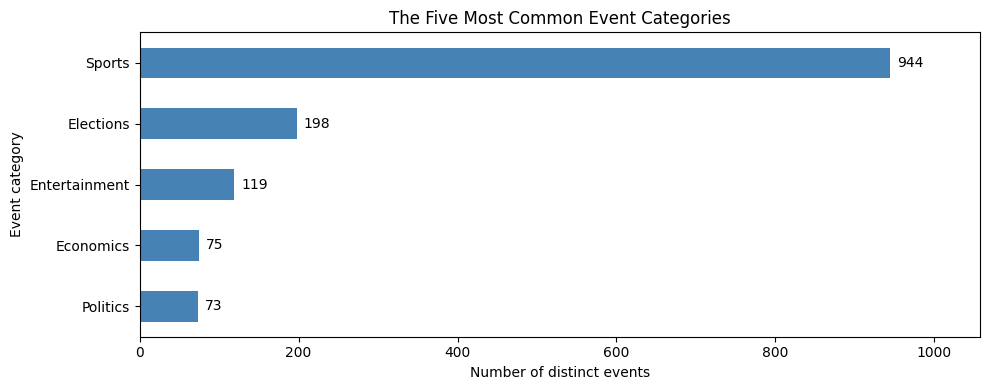

In [ ]:
# Select the five categories with the most events
plot_data = (
    category_event_counts
    .nlargest(5, "event_count")
    .sort_values("event_count")
)

ax = plot_data.plot(
    kind="barh",
    x="event_category",
    y="event_count",
    figsize=(10, 4),
    legend=False,
    title="The Five Most Common Event Categories",
    color="steelblue",
)

ax.set_xlabel("Number of distinct events")
ax.set_ylabel("Event category")
ax.set_xlim(0, plot_data["event_count"].max() * 1.12)

# Add count labels just beyond each bar
for bar in ax.patches:
    ax.annotate(
        f"{int(bar.get_width()):,}",
        (bar.get_width(), bar.get_y() + bar.get_height() / 2),
        xytext=(5, 0),
        textcoords="offset points",
        va="center",
    )

plt.tight_layout()
plt.show()

# Step 7 — Explore price and size by side
Summaries and plots show ranges, zeros, and unusual values. They do not establish whether size is an order, snapshot, or update.

price                                                        \
         count      mean       std     min   25%   50%    75%    max   
side                                                                   
BUY   309986.0  0.320431  0.252232  0.0001  0.09  0.28  0.492  0.990   
SELL  318527.0  0.496574  0.308548  0.0010  0.22  0.48  0.800  0.999   

          size                                                      \
         count         mean           std  min  25%    50%     75%   
side                                                                 
BUY   309986.0  5055.747652  45980.351740  0.0  1.2   70.0   815.0   
SELL  318527.0  9411.767774  79197.318231  0.0  4.0  150.0  1643.0   

                   
              max  
side               
BUY   10063395.93  
SELL   6408490.75

Zero-size rows: 138866
Negative-size rows: 0


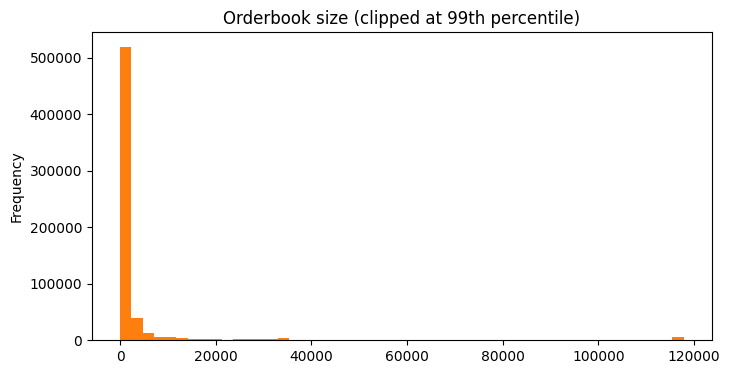

In [ ]:
price_size_summary = eda_df.groupby("side")[["price", "size"]].describe()
display(price_size_summary)

print("Zero-size rows:", int((eda_df["size"] == 0).sum()))
print("Negative-size rows:", int((eda_df["size"] < 0).sum()))

eda_df["price"].plot(kind="hist", bins=50, figsize=(8, 4), title="Orderbook price distribution");
eda_df["size"].clip(upper=eda_df["size"].quantile(.99)).plot(kind="hist", bins=50, figsize=(8, 4), title="Orderbook size (clipped at 99th percentile)");

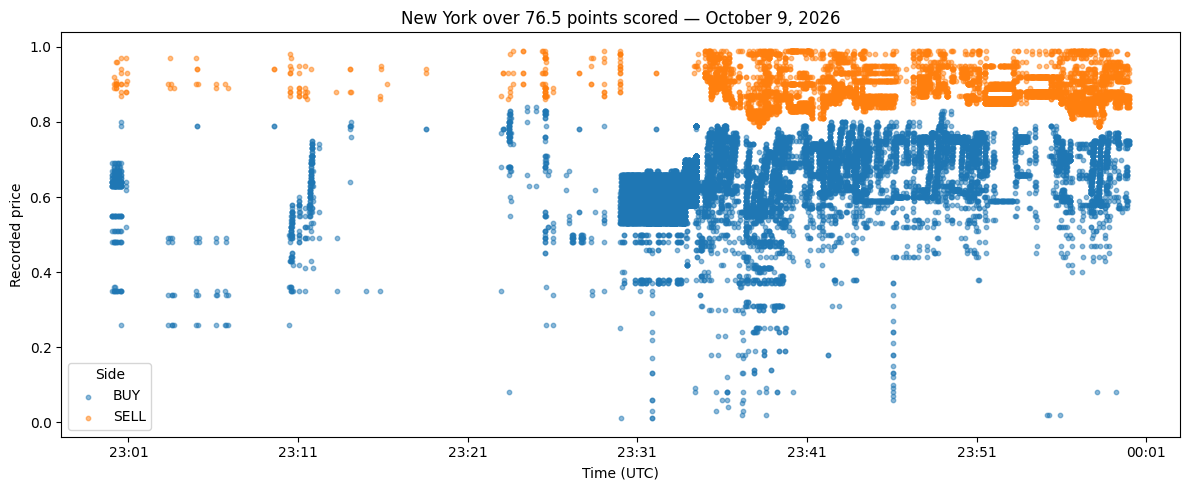

In [ ]:
market_date = (
    market_rows["orderbook_time"].min()
    .strftime("%B %d, %Y")
    .replace(" 0", " ")
)

fig, ax = plt.subplots(figsize=(12, 5))

for side, color in [("BUY", "tab:blue"), ("SELL", "tab:orange")]:
    side_rows = market_rows[market_rows["side"] == side]
    ax.scatter(
        side_rows["orderbook_time"],
        side_rows["price"],
        s=10,
        alpha=0.5,
        label=side,
        color=color,
    )

ax.set(
    title=f"{market_title} — {market_date}",
    xlabel="Time (UTC)",
    ylabel="Recorded price",
)
ax.xaxis.set_major_locator(mdates.MinuteLocator(interval=10, tz=mdates.UTC))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=mdates.UTC))
ax.legend(title="Side")
plt.tight_layout()
plt.show()

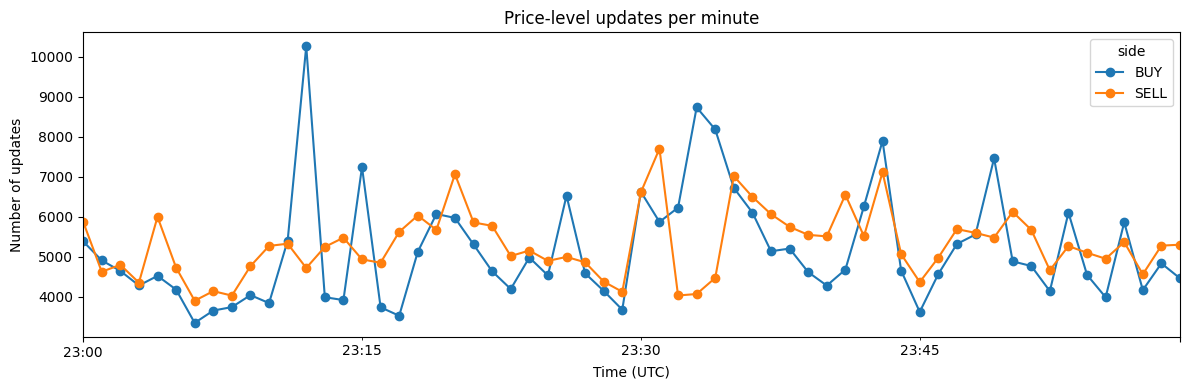

In [ ]:
minute_side_counts = (
    eda_df.assign(minute=eda_df["orderbook_time"].dt.floor("min"))
    .groupby(["minute", "side"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=["BUY", "SELL"], fill_value=0)
)

minute_side_counts.plot(
    figsize=(12, 4),
    marker="o",
    title="Price-level updates per minute",
    xlabel="Time (UTC)",
    ylabel="Number of updates",
)

plt.tight_layout()
plt.show()

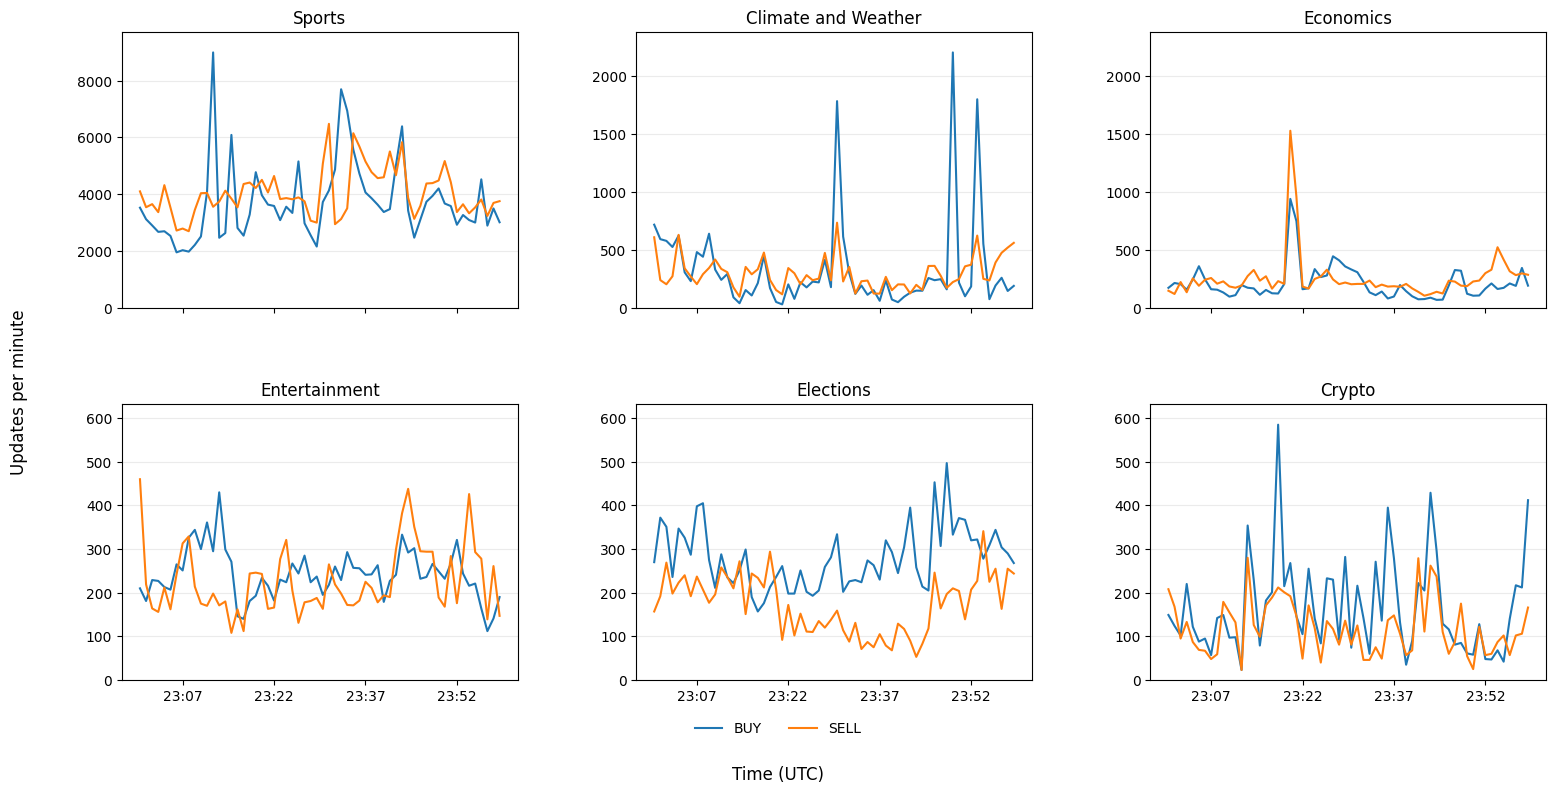

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

# Exclude rows without a category, timestamp, or side
plot_df = eda_df.dropna(
    subset=["event_category", "orderbook_time", "side"]
).copy()

categories = [
    "Sports",
    "Climate and Weather",
    "Economics",
    "Entertainment",
    "Elections",
    "Crypto",
]

minute_range = pd.date_range(
    start=plot_df["orderbook_time"].min().floor("min"),
    end=plot_df["orderbook_time"].max().floor("min"),
    freq="min",
)

# Count BUY and SELL updates per minute for each category
counts_by_category = {}

for category in categories:
    category_df = plot_df.loc[
        plot_df["event_category"] == category
    ].copy()

    category_df["minute"] = category_df["orderbook_time"].dt.floor("min")

    counts_by_category[category] = (
        category_df.groupby(["minute", "side"])
        .size()
        .unstack(fill_value=0)
        .reindex(columns=["BUY", "SELL"], fill_value=0)
        .reindex(minute_range, fill_value=0)
    )

# Arrange the six panels in two rows and three columns
panel_order = [
    "Sports",
    "Climate and Weather",
    "Economics",
    "Entertainment",
    "Elections",
    "Crypto",
]

fig, axes_array = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(16, 8),
    sharex=True,
    sharey=False,
)
axes = dict(zip(panel_order, axes_array.flat))

# Categories in each group share the same y-axis range
scale_groups = [
    ["Sports"],
    ["Climate and Weather", "Economics"],
    ["Entertainment", "Elections", "Crypto"],
]

for group in scale_groups:
    group_max = max(
        counts_by_category[category].to_numpy().max()
        for category in group
    )
    y_max = group_max * 1.08 if group_max > 0 else 1

    for category in group:
        ax = axes[category]
        counts = counts_by_category[category]

        ax.plot(
            counts.index,
            counts["BUY"],
            label="BUY",
            color="tab:blue",
        )
        ax.plot(
            counts.index,
            counts["SELL"],
            label="SELL",
            color="tab:orange",
        )

        ax.set_title(category)
        ax.set_ylim(0, y_max)
        ax.grid(axis="y", alpha=0.25)

# Format the shared time axis
axes["Entertainment"].xaxis.set_major_locator(
    mdates.MinuteLocator(interval=15, tz=mdates.UTC)
)
axes["Entertainment"].xaxis.set_major_formatter(
    mdates.DateFormatter("%H:%M", tz=mdates.UTC)
)

fig.supxlabel("Time (UTC)")
fig.supylabel("Updates per minute")

# One shared legend below the panels
handles, labels = axes["Sports"].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.055),
    ncol=2,
    frameon=False,
)

fig.subplots_adjust(
    bottom=0.14,
    left=0.09,
    right=0.98,
    top=0.95,
    hspace=0.35,
    wspace=0.3,
)

plt.show()

# Step 8 — Inspect hourly candle coverage and timing
observed_at may be later than candle_end_time: the candle describes that earlier period but was observed later.

In [ ]:
print("Candle rows:", f"{len(candles_df):,}")
print("Markets with candles:", candles_df["market_slug"].nunique())
print("Candle end-time range:", candles_df["candle_end_time"].min(), "to", candles_df["candle_end_time"].max())
print("Observed-at range:    ", candles_df["observed_at"].min(), "to", candles_df["observed_at"].max())

candle_timing = candles_df.dropna(subset=["observed_at", "candle_end_time"]).copy()
candle_timing["observation_delay_hours"] = (pd.to_datetime(candle_timing["observed_at"], utc=True) - pd.to_datetime(candle_timing["candle_end_time"], utc=True)).dt.total_seconds() / 3600
display(candle_timing["observation_delay_hours"].describe().to_frame())

print("Candle rows with missing price_close:", int(candles_df["price_close"].isna().sum()))

Candle rows: 105,155
Markets with candles: 2055
Candle end-time range: 2026-10-09 00:00:00+00:00 to 2026-10-27 20:00:00+00:00
Observed-at range:     2026-10-11 16:28:51.373659+00:00 to 2026-10-27 23:12:24.886922+00:00


,observation_delay_hours
count,105155.000000
mean,126.708868
std,111.761012
min,0.184866
25%,3.626545
50%,119.711504
75%,168.573980
max,393.206913


Candle rows with missing price_close: 86615


# Step 9 — Review the combined orderbook and candle data
`orderbook_with_candles` aligns each row to the latest candle ending at or before its timestamp. This gives retrospective context; because `observed_at` may be later, do not assume candle values were known in real time.

In [ ]:
print("Orderbook rows after time alignment:", f"{len(orderbook_with_candles):,}")

matched_candles = orderbook_with_candles["candle_end_time"].notna()

print("Rows with a prior candle:", f"{int(matched_candles.sum()):,}")
print("Rows without a prior candle:", f"{int((~matched_candles).sum()):,}")

display(orderbook_with_candles[["orderbook_time", "asset_id", "side", "price", "size", "candle_end_time", "yes_bid_close", "yes_ask_close", "price_close", "volume", "open_interest", "observed_at"]].head(10))

Orderbook rows after time alignment: 628,513
Rows with a prior candle: 628,374
Rows without a prior candle: 139


,orderbook_time,asset_id,side,price,size,candle_end_time,yes_bid_close,yes_ask_close,price_close,volume,open_interest,observed_at
0,2026-10-09 23:00:00.012000+00:00,KXAAAGASDGA-26OCT10-3.8250,BUY,0.10,0.00,2026-10-09 23:00:00+00:00,0.1200,0.3700,0.1600,27.98,21.98,2026-10-15 10:02:55.592846+00:00
1,2026-10-09 23:00:00.012000+00:00,KXAAAGASDGA-26OCT10-3.8250,BUY,0.12,6.00,2026-10-09 23:00:00+00:00,0.1200,0.3700,0.1600,27.98,21.98,2026-10-15 10:02:55.592846+00:00
2,2026-10-09 23:00:00.027000+00:00,KXNFLTDPROT-26OCT12BUFLAR-BUFJALLEN17-2,BUY,0.09,0.00,2026-10-09 23:00:00+00:00,0.1000,0.1700,None,0.00,105.88,2026-10-15 12:44:33.767269+00:00
3,2026-10-09 23:00:00.027000+00:00,KXNFLGAME-26OCT11CHIGB-CHI,SELL,0.53,1861303.46,2026-10-09 23:00:00+00:00,0.5200,0.5300,0.5300,7936.32,873145.19,2026-10-15 12:28:35.382338+00:00
4,2026-10-09 23:00:00.027000+00:00,KXNFLFFPTS-26OCT11CHIGB-CHICHIDST-6P9,BUY,0.10,0.00,2026-10-09 23:00:00+00:00,0.1200,0.3600,None,0.00,299.44,2026-10-15 12:28:11.358062+00:00
5,2026-10-09 23:00:00.054000+00:00,KXLIGAMXBTTS-26OCT09PUELEO-BTTS,BUY,0.03,522.10,2026-10-09 23:00:00+00:00,0.5600,0.5700,0.5700,1674.40,2409.42,2026-10-15 11:22:00.033951+00:00
6,2026-10-09 23:00:00.070000+00:00,KXLIGAMXBTTS-26OCT09PUELEO-BTTS,SELL,0.97,492.10,2026-10-09 23:00:00+00:00,0.5600,0.5700,0.5700,1674.40,2409.42,2026-10-15 11:22:00.033951+00:00
7,2026-10-09 23:00:00.070000+00:00,KXNFLREC-26OCT11PHIJAC-JACBTHOMAS7-4,SELL,0.20,5.00,2026-10-09 23:00:00+00:00,0.1700,0.2000,None,0.00,1573.00,2026-10-15 12:35:23.838056+00:00
8,2026-10-09 23:00:00.070000+00:00,KXNFLTDPROT-26OCT12BUFLAR-BUFJALLEN17-2,BUY,0.10,15.00,2026-10-09 23:00:00+00:00,0.1000,0.1700,None,0.00,105.88,2026-10-15 12:44:33.767269+00:00
9,2026-10-09 23:00:00.070000+00:00,KXNFLREC-26OCT11PHIJAC-JACBTHOMAS7-4,BUY,0.16,460.00,2026-10-09 23:00:00+00:00,0.1700,0.2000,None,0.00,1573.00,2026-10-15 12:35:23.838056+00:00


## Close the Postgres connection

Re-run the Postgres connection cell before running further database queries.

In [ ]:
con.close()
print("Postgres connection closed.")

# Appendix:

## Key columns

| Column | Meaning |
|---|---|
| `ts_ms` | Timestamp in milliseconds |
| `asset_id` | Asset identifier in the orderbook data |
| `market` | Market identifier in the orderbook data |
| `side` | Order side: `BUY` or `SELL` |
| `price` | Price recorded for the order |
| `size` | Quantity recorded for the order |
| `ticker` | Market or event identifier |
| `slug` | Text identifier for a market or event |
| `title` | Readable market or event name |
| `event_slug` | Identifier of the event associated with a market |
| `market_slug` | Identifier of the market associated with a candle |
| `condition_id` | Market condition identifier |
| `end_time` | Candle interval end time |
| `interval_minutes` | Candle interval length in minutes |
| `yes_bid_*` | YES bid price summaries for the candle: open, high, low, close |
| `yes_ask_*` | YES ask price summaries for the candle: open, high, low, close |
| `price_*` | Price summaries for the candle: open, high, low, close |
| `volume` | Trading volume recorded for the candle |
| `open_interest` | Open contracts recorded for the candle |
| `start_date` / `end_date` | Market or event start and end times |
| `active` / `closed` / `archived` | Market or event status flags |
| `best_bid` / `best_ask` | Current best bid and ask prices |
| `last_trade_price` | Most recent trade price |

In [ ]:
wnba_markets = (
    eda_df.loc[
        eda_df["event_slug"].fillna("").str.startswith("KXWNBA"),
        ["asset_id", "market_title", "event_slug", "event_title"],
    ]
    .drop_duplicates("asset_id")
)

chosen_market = wnba_markets.sample(n=1, random_state=42).iloc[0]
market_id = chosen_market["asset_id"]

market_rows = (
    eda_df[eda_df["asset_id"] == market_id]
    .sort_values("orderbook_time")
)

print("Event:", chosen_market["event_title"])
print("Market:", chosen_market["market_title"])
print("Records in this file:", f"{len(market_rows):,}")

market_rows[["orderbook_time", "side", "price"]].head(10)

Event: Golden State vs Las Vegas: Points
Market: Chelsea Gray: 15+ points
Records in this file: 347


,orderbook_time,side,price
541043,2026-10-09 23:00:35.723000+00:00,SELL,0.35
541044,2026-10-09 23:00:53.035000+00:00,BUY,0.01
541045,2026-10-09 23:00:53.035000+00:00,BUY,0.30
541046,2026-10-09 23:00:53.036000+00:00,SELL,0.33
541047,2026-10-09 23:00:53.036000+00:00,SELL,0.34
541048,2026-10-09 23:00:57.343000+00:00,SELL,0.39
541049,2026-10-09 23:01:25.221000+00:00,BUY,0.30
541050,2026-10-09 23:01:25.221000+00:00,SELL,0.33
541051,2026-10-09 23:01:25.238000+00:00,BUY,0.01
541052,2026-10-09 23:01:25.238000+00:00,BUY,0.02


In [ ]:
print("Event:", chosen_market["event_title"])
print("Market:", chosen_market["market_title"])
print("Records:", f"{len(market_rows):,}")
print("Time range:",
      market_rows["orderbook_time"].min(),
      "to",
      market_rows["orderbook_time"].max())

side_summary = (
    market_rows.groupby("side")["price"]
    .agg(
        record_count="count",
        distinct_prices="nunique",
        min_price="min",
        median_price="median",
        max_price="max",
    )
)

display(side_summary)

Event: Golden State vs Las Vegas: Points
Market: Chelsea Gray: 15+ points
Records: 347
Time range: 2026-10-09 23:00:35.723000+00:00 to 2026-10-09 23:55:22.772000+00:00


,record_count,distinct_prices,min_price,median_price,max_price
side,,,,,
BUY,185,14,0.01,0.28,0.32
SELL,162,12,0.32,0.35,0.98


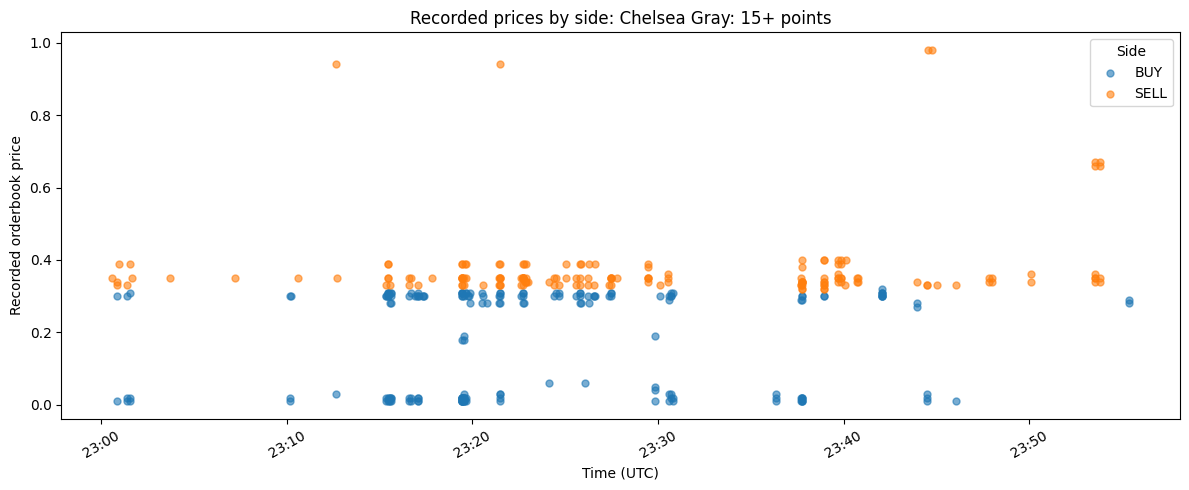

In [ ]:
fig, ax = plt.subplots(figsize=(12, 5))

for side, color in [("BUY", "tab:blue"), ("SELL", "tab:orange")]:
    side_rows = market_rows[market_rows["side"] == side]
    ax.scatter(
        side_rows["orderbook_time"],
        side_rows["price"],
        s=25,
        alpha=0.6,
        label=side,
        color=color,
    )

ax.set(
    title=f"Recorded prices by side: {chosen_market['market_title']}",
    xlabel="Time (UTC)",
    ylabel="Recorded orderbook price",
)
ax.legend(title="Side")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=mdates.UTC))
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Original records: 347
Records after removing zero-size rows: 322
Removed: 25


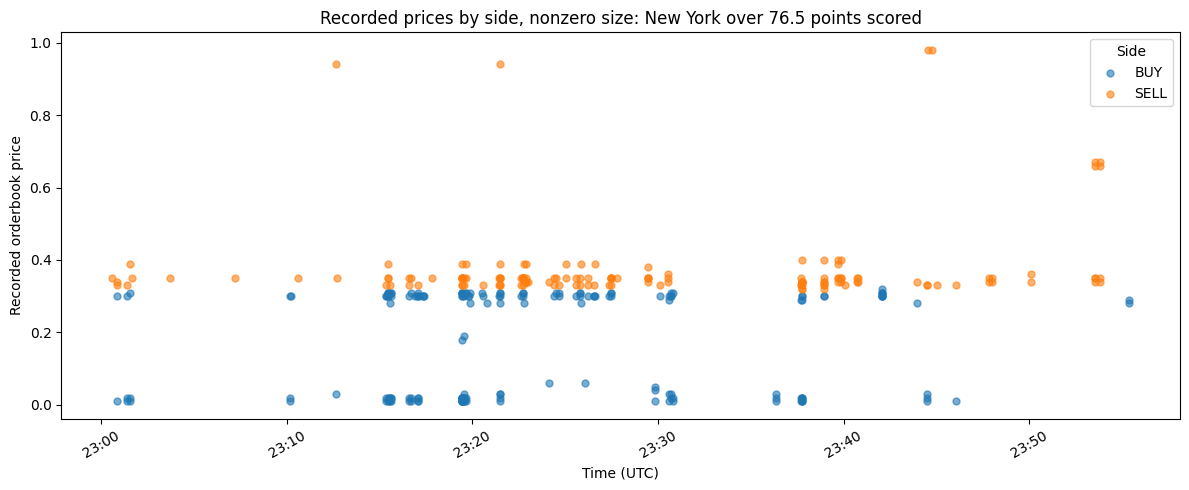

In [ ]:
market_rows_nonzero = market_rows[market_rows["size"] != 0]

print(f"Original records: {len(market_rows):,}")
print(f"Records after removing zero-size rows: {len(market_rows_nonzero):,}")
print(f"Removed: {(market_rows['size'] == 0).sum():,}")

fig, ax = plt.subplots(figsize=(12, 5))

for side, color in [("BUY", "tab:blue"), ("SELL", "tab:orange")]:
    side_rows = market_rows_nonzero[market_rows_nonzero["side"] == side]
    ax.scatter(
        side_rows["orderbook_time"],
        side_rows["price"],
        s=25,
        alpha=0.6,
        label=side,
        color=color,
    )

ax.set(
    title=f"Recorded prices by side, nonzero size: {market_title}",
    xlabel="Time (UTC)",
    ylabel="Recorded orderbook price",
)
ax.legend(title="Side")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=mdates.UTC))
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

,markets,median_records,q25,q75
event_category,,,,
Crypto,18,165.0,49.50,729.50
Climate and Weather,52,116.5,39.00,533.00
Commodities,14,78.5,38.25,412.00
Sports,1254,73.0,17.00,174.00
Economics,87,48.0,14.00,332.00
Science and Technology,43,45.0,12.00,85.50
Financials,79,14.0,5.00,37.50
Entertainment,174,13.0,6.00,73.25
Politics,82,12.0,7.00,21.00


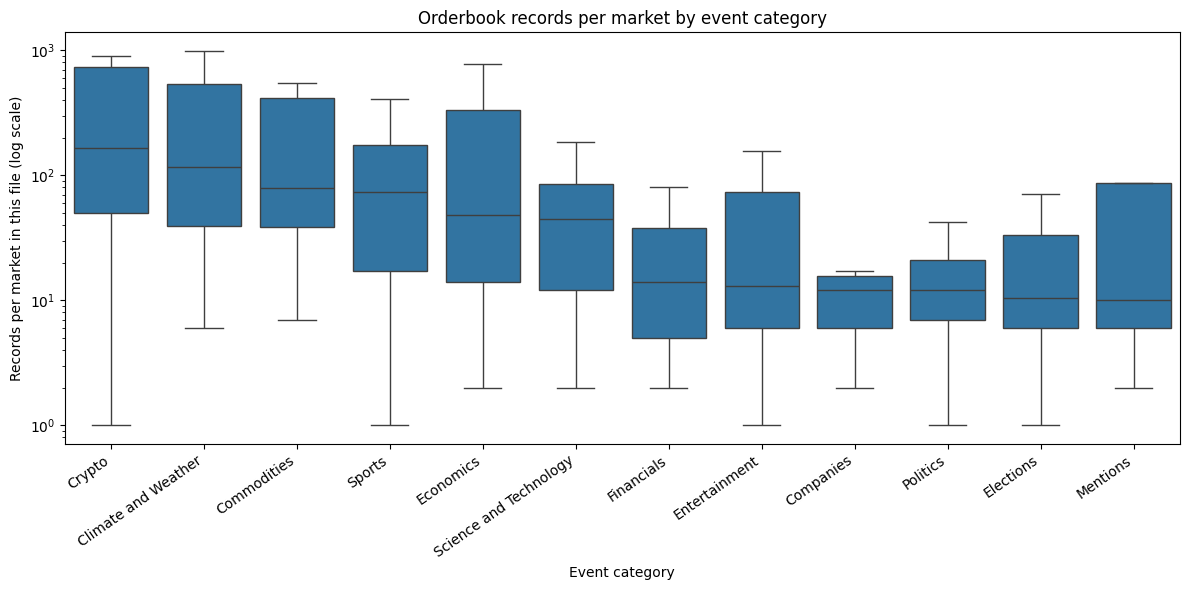

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Count orderbook records for each market.
market_record_counts = (
    eda_df.dropna(subset=["asset_id", "event_category"])
    .groupby(["event_category", "asset_id"])
    .size()
    .reset_index(name="record_count")
)

# Summarize markets per category, and show sample sizes.
category_summary = (
    market_record_counts.groupby("event_category")["record_count"]
    .agg(
        markets="count",
        median_records="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
    )
    .sort_values("median_records", ascending=False)
)

display(category_summary)

# Exclude categories with fewer than five markets from the plot.
keep_categories = category_summary.query("markets >= 5").index
plot_data = market_record_counts[
    market_record_counts["event_category"].isin(keep_categories)
]
category_order = (
    plot_data.groupby("event_category")["record_count"]
    .median()
    .sort_values(ascending=False)
    .index
)

fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(
    data=plot_data,
    x="event_category",
    y="record_count",
    order=category_order,
    showfliers=False,
    ax=ax,
)

ax.set_yscale("log")
ax.set_title("Orderbook records per market by event category")
ax.set_xlabel("Event category")
ax.set_ylabel("Records per market in this file (log scale)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

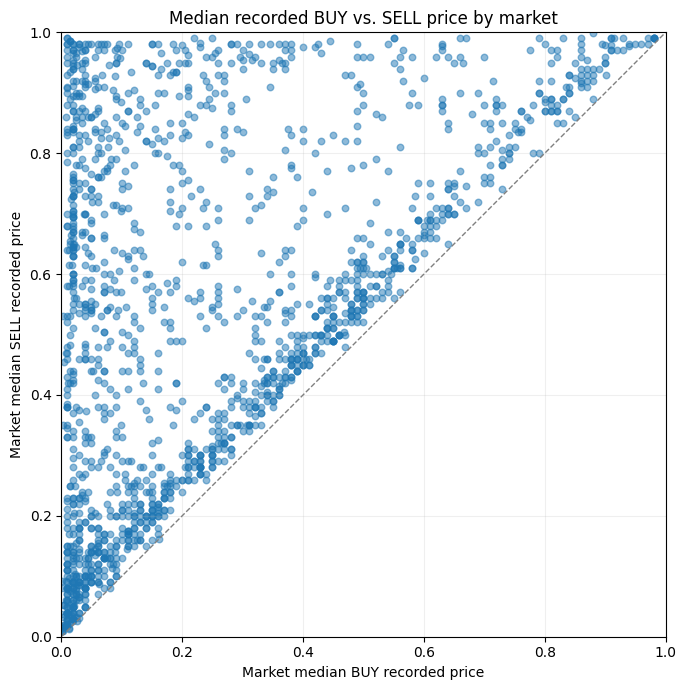

Markets shown (with both sides): 1,640


In [ ]:
# Calculate one median recorded price per market for each side
market_side_medians = (
    eda_df.dropna(subset=["asset_id", "side", "price"])
    .groupby(["asset_id", "side"])["price"]
    .median()
    .unstack("side")
)

# Keep markets that have records for both BUY and SELL
market_side_medians = market_side_medians.dropna(subset=["BUY", "SELL"])

fig, ax = plt.subplots(figsize=(7, 7))

ax.scatter(
    market_side_medians["BUY"],
    market_side_medians["SELL"],
    alpha=0.5,
    s=22,
)

# Reference line: BUY and SELL medians are equal
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", linewidth=1)

ax.set(
    xlim=(0, 1),
    ylim=(0, 1),
    xlabel="Market median BUY recorded price",
    ylabel="Market median SELL recorded price",
    title="Median recorded BUY vs. SELL price by market",
)
ax.set_aspect("equal", adjustable="box")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print(f"Markets shown (with both sides): {len(market_side_medians):,}")

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import textwrap

# Keep sports records with a market, side, and recorded price
sports = eda_df.loc[
    eda_df["event_category"].eq("Sports")
].dropna(subset=["asset_id", "side", "price"]).copy()

# Calculate one median recorded price per market and side
price_medians = (
    sports.groupby(["asset_id", "side"])["price"]
    .median()
    .unstack("side")
)

# Add titles and total row counts
market_info = (
    sports.groupby("asset_id")
    .agg(
        market_title=("market_title", "first"),
        record_count=("asset_id", "size"),
    )
)

# Keep markets that have both BUY and SELL records
plot_data = (
    price_medians
    .join(market_info)
    .dropna(subset=["BUY", "SELL"])
)

# Select the 15 markets with the most recorded rows
plot_data = plot_data.nlargest(15, "record_count").copy()

# Calculate SELL median minus BUY median; sort largest gap first
plot_data["gap"] = plot_data["SELL"] - plot_data["BUY"]
plot_data = plot_data.sort_values("gap", ascending=False)

# Wrap long labels; use the market ID if the title is missing
labels = [
    textwrap.fill(str(title), width=38) if pd.notna(title) else str(market_id)
    for market_id, title in zip(plot_data.index, plot_data["market_title"])
]

fig, ax = plt.subplots(figsize=(11, 9))
y_positions = range(len(plot_data))

# Connect each market's two medians
for position, (_, row) in enumerate(plot_data.iterrows()):
    ax.plot(
        [row["BUY"], row["SELL"]],
        [position, position],
        color="#c7cdd4",
        linewidth=2,
        zorder=1,
    )

# Plot each side's median
ax.scatter(
    plot_data["BUY"],
    y_positions,
    label="BUY median",
    color="#2878B5",
    s=65,
    edgecolor="white",
    linewidth=0.7,
    zorder=2,
)
ax.scatter(
    plot_data["SELL"],
    y_positions,
    label="SELL median",
    color="#E07A24",
    s=65,
    edgecolor="white",
    linewidth=0.7,
    zorder=2,
)

# Show the median gap as a separate value column
for position, gap in enumerate(plot_data["gap"]):
    ax.text(
        1.035,
        position,
        f"{gap:+.2f}",
        va="center",
        ha="left",
        fontsize=9,
        color="#444444",
    )

ax.set_yticks(list(y_positions))
ax.set_yticklabels(labels)
ax.invert_yaxis()

ax.set_xlim(0, 1.13)
ax.set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_xlabel("Median recorded price")
ax.set_ylabel("Market")

ax.set_title(
    "Recorded BUY and SELL median prices",
    loc="left",
    fontsize=15,
    weight="bold",
    pad=24,
)
ax.text(
    0,
    1.015,
    "15 sports markets with the most rows in the one-hour Parquet sample",
    transform=ax.transAxes,
    fontsize=10,
    color="#555555",
)

# Label the gap-value column
ax.text(
    1.035,
    1.01,
    "SELL − BUY",
    transform=ax.transAxes,
    ha="left",
    va="bottom",
    fontsize=9,
    weight="bold",
    color="#444444",
)

ax.grid(axis="x", color="#e6e9ed", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)

ax.legend(
    frameon=False,
    loc="lower right",
    bbox_to_anchor=(1.0, 1.03),
    ncol=2,
)

ax.tick_params(axis="y", length=0)

fig.text(
    0.01,
    0.01,
    "Each dot is a market-level median. Prices are recorded values, not confirmed executed trades.",
    fontsize=9,
    color="#555555",
)

plt.tight_layout(rect=[0, 0.04, 1, 0.98])
plt.show()

In [ ]:
probe = joined_df.copy()

probe["price_num"] = pd.to_numeric(probe["price"], errors="coerce")
probe["size_num"] = pd.to_numeric(probe["size"], errors="coerce")

print(f"Rows: {len(probe):,}")
print(f"Exact duplicate rows: {probe.duplicated().sum():,}")
print(f"Rows with size = 0: {(probe['size_num'] == 0).sum():,}")
print(f"Rows with missing size: {probe['size_num'].isna().sum():,}")

# How many rows, sides, and prices occur for the same market at the same timestamp?
rows_per_timestamp = (
    probe.groupby(["asset_id", "ts_ms"])
    .agg(
        rows=("price_num", "size"),
        sides=("side", "nunique"),
        distinct_prices=("price_num", "nunique"),
    )
)

print("\nRows per market-timestamp:")
display(rows_per_timestamp["rows"].describe())

print("\nExamples of market-timestamps with the most rows:")
display(rows_per_timestamp.sort_values("rows", ascending=False).head(10))

print("\nSummary by side:")
display(
    probe.groupby("side")
    .agg(
        rows=("side", "size"),
        distinct_prices=("price_num", "nunique"),
        zero_size_rows=("size_num", lambda s: (s == 0).sum()),
        median_size=("size_num", "median"),
    )
)

Rows: 628,513
Exact duplicate rows: 0
Rows with size = 0: 138,866
Rows with missing size: 0

Rows per market-timestamp:


,rows
count,420840.000000
mean,1.493473
std,0.930981
min,1.000000
25%,1.000000
50%,1.000000
75%,2.000000
max,89.000000



Examples of market-timestamps with the most rows:


,,rows,sides,distinct_prices
asset_id,ts_ms,,,
KXNHLTEAMTOTAL-26OCT09NYRWSH-NYR2,1791587280261,89,2,89
KXUSL1H-26OCT09LEXTUL-TIE,1791588603187,88,2,88
KXLIGAMXSPREAD-26OCT09TIGTOL-TIG2,1791587045259,76,1,76
KXNHL3PSPREAD-26OCT09SEADET-DET2,1791588554343,73,1,73
KXLIGAMXTOTAL-26OCT09PUELEO-6,1791587122554,71,1,71
KXNCAAF1HSPREAD-26OCT09ISUBYU-ISU4,1791589115018,70,1,70
KXAHLGAME-26OCT091900TORBRI-BRI,1791586801643,69,2,69
KXJ2LEAGUESPREAD-26OCT10VORIMA-VOR2,1791589522443,68,2,68
KXNHLTOTAL-26OCT09ANAWPG-8,1791589866769,67,1,67



Summary by side:


,rows,distinct_prices,zero_size_rows,median_size
side,,,,
BUY,309986,332,71934,70.0
SELL,318527,452,66932,150.0


In [ ]:
print(rows_per_timestamp.sort_values("rows", ascending=False).head(10).to_string())

                                                   rows  sides  distinct_prices
asset_id                            ts_ms                                      
KXNHLTEAMTOTAL-26OCT09NYRWSH-NYR2   1791587280261    89      2               89
KXUSL1H-26OCT09LEXTUL-TIE           1791588603187    88      2               88
KXLIGAMXSPREAD-26OCT09TIGTOL-TIG2   1791587045259    76      1               76
KXNHL3PSPREAD-26OCT09SEADET-DET2    1791588554343    73      1               73
KXLIGAMXTOTAL-26OCT09PUELEO-6       1791587122554    71      1               71
KXNCAAF1HSPREAD-26OCT09ISUBYU-ISU4  1791589115018    70      1               70
KXAHLGAME-26OCT091900TORBRI-BRI     1791586801643    69      2               69
KXJ2LEAGUESPREAD-26OCT10VORIMA-VOR2 1791589522443    68      2               68
KXNHLTOTAL-26OCT09ANAWPG-8          1791589866769    67      1               67
KXNCAAF1HSPREAD-26OCT10EMUAKR-EMU15 1791589522443    64      1               64


In [ ]:
market_id, timestamp_ms = rows_per_timestamp["rows"].idxmax()

same_timestamp = probe.loc[
    (probe["asset_id"] == market_id)
    & (probe["ts_ms"] == timestamp_ms),
    ["asset_id", "ts_ms", "side", "price_num", "size_num"],
].sort_values(["side", "price_num"])

print("Market:", market_id)
print("Time:", pd.to_datetime(timestamp_ms, unit="ms", utc=True))
print("Rows:", len(same_timestamp))
print("Zero-size rows:", (same_timestamp["size_num"] == 0).sum())

display(same_timestamp)

Market: KXNHLTEAMTOTAL-26OCT09NYRWSH-NYR2
Time: 2026-10-09 23:08:00.261000+00:00
Rows: 89
Zero-size rows: 70


,asset_id,ts_ms,side,price_num,size_num
410020,KXNHLTEAMTOTAL-26OCT09NYRWSH-NYR2,1791587280261,BUY,0.01,0.00
410021,KXNHLTEAMTOTAL-26OCT09NYRWSH-NYR2,1791587280261,BUY,0.02,2.50
410022,KXNHLTEAMTOTAL-26OCT09NYRWSH-NYR2,1791587280261,BUY,0.03,1.66
410023,KXNHLTEAMTOTAL-26OCT09NYRWSH-NYR2,1791587280261,BUY,0.04,1.25
410024,KXNHLTEAMTOTAL-26OCT09NYRWSH-NYR2,1791587280261,BUY,0.05,2.00
...,...,...,...,...,...
410104,KXNHLTEAMTOTAL-26OCT09NYRWSH-NYR2,1791587280261,SELL,0.95,3.00
410105,KXNHLTEAMTOTAL-26OCT09NYRWSH-NYR2,1791587280261,SELL,0.96,1.25
410106,KXNHLTEAMTOTAL-26OCT09NYRWSH-NYR2,1791587280261,SELL,0.97,91.66
410107,KXNHLTEAMTOTAL-26OCT09NYRWSH-NYR2,1791587280261,SELL,0.98,52.50


In [ ]:
levels = same_timestamp.copy()

print("Price levels by side:")
display(
    levels.groupby("side").agg(
        price_levels=("price_num", "size"),
        levels_with_positive_size=("size_num", lambda s: (s > 0).sum()),
        zero_size_levels=("size_num", lambda s: (s == 0).sum()),
        total_size=("size_num", "sum"),
    )
)

# Find the highest positive BUY price and lowest positive SELL price
positive_levels = levels[levels["size_num"] > 0]

for side in ["BUY", "SELL"]:
    side_levels = positive_levels[positive_levels["side"] == side]
    if side_levels.empty:
        print(f"No positive-size {side} levels")
        continue

    best = (
        side_levels.loc[side_levels["price_num"].idxmax()]
        if side == "BUY"
        else side_levels.loc[side_levels["price_num"].idxmin()]
    )
    print(
        f"Best positive-size {side}: "
        f"price={best['price_num']:.2f}, size={best['size_num']}"
    )

Price levels by side:


,price_levels,levels_with_positive_size,zero_size_levels,total_size
side,,,,
BUY,71,12,59,386.91
SELL,18,7,11,598.41


Best positive-size BUY: price=0.71, size=32.0
Best positive-size SELL: price=0.82, size=35.0


In [ ]:
book_rows = joined_df.copy()
book_rows["size_num"] = pd.to_numeric(book_rows["size"], errors="coerce")
book_rows["price_num"] = pd.to_numeric(book_rows["price"], errors="coerce")

# Count rows and price levels for each market at each timestamp
market_times = (
    book_rows.groupby(["asset_id", "ts_ms"])
    .agg(
        rows=("price_num", "size"),
        distinct_prices=("price_num", "nunique"),
        zero_size_rows=("size_num", lambda s: (s == 0).sum()),
    )
    .reset_index()
    .sort_values(["asset_id", "ts_ms"])
)

# Mark each market's first timestamp; later groups may be updates
market_times["time_number"] = (
    market_times.groupby("asset_id").cumcount()
)

first_groups = market_times[market_times["time_number"] == 0]
later_groups = market_times[market_times["time_number"] > 0]

comparison = pd.DataFrame(
    {
        "First timestamp per market": [
            len(first_groups),
            first_groups["rows"].median(),
            (first_groups["rows"] >= 10).mean() * 100,
        ],
        "Later timestamps": [
            len(later_groups),
            later_groups["rows"].median(),
            (later_groups["rows"] >= 10).mean() * 100,
        ],
    },
    index=["Market-timestamp groups", "Median rows per group", "% with 10+ rows"],
)

display(comparison)

# Inspect the market whose first timestamp has the most rows
largest_first_market = first_groups.loc[first_groups["rows"].idxmax(), "asset_id"]
print("Market with the largest first timestamp group:", largest_first_market)

display(
    market_times.loc[
        market_times["asset_id"] == largest_first_market
    ].head(20)
)

,First timestamp per market,Later timestamps
Market-timestamp groups,2056.0,418784.000000
Median rows per group,1.0,1.000000
% with 10+ rows,0.0,0.065189


Market with the largest first timestamp group: SENATEAK-26-D


,asset_id,ts_ms,rows,distinct_prices,zero_size_rows,time_number
418660,SENATEAK-26-D,1791587271141,7,7,0,0
418661,SENATEAK-26-D,1791587271144,3,3,0,1
418662,SENATEAK-26-D,1791587279544,6,6,4,2
418663,SENATEAK-26-D,1791587279553,5,5,0,3
418664,SENATEAK-26-D,1791587646415,1,1,1,4
418665,SENATEAK-26-D,1791587646471,1,1,0,5
418666,SENATEAK-26-D,1791587776406,1,1,0,6
418667,SENATEAK-26-D,1791587841187,1,1,0,7
418668,SENATEAK-26-D,1791587874036,1,1,0,8
418669,SENATEAK-26-D,1791587994305,1,1,0,9


In [ ]:
book_rows = joined_df.copy()
book_rows["_row_order"] = range(len(book_rows))
book_rows["price_num"] = pd.to_numeric(book_rows["price"], errors="coerce")
book_rows["size_num"] = pd.to_numeric(book_rows["size"], errors="coerce")

print("Negative-size rows:", (book_rows["size_num"] < 0).sum())

# Follow each market/side/price level through the hour
level_history = book_rows.sort_values(
    ["asset_id", "side", "price_num", "ts_ms", "_row_order"]
).copy()

level_history["previous_size"] = (
    level_history.groupby(["asset_id", "side", "price_num"])["size_num"].shift()
)

zero_rows = level_history[level_history["size_num"] == 0]
zero_after_prior = zero_rows.dropna(subset=["previous_size"])

print(f"Zero-size rows: {len(zero_rows):,}")
print(f"Zero rows with a prior record at the same level: {len(zero_after_prior):,}")
print(
    "Of those, preceded by positive size:",
    f"{(zero_after_prior['previous_size'] > 0).sum():,}",
)

display(
    zero_after_prior[
        ["asset_id", "ts_ms", "side", "price_num", "previous_size", "size_num"]
    ].head(15)
)

Negative-size rows: 0
Zero-size rows: 138,866
Zero rows with a prior record at the same level: 132,652
Of those, preceded by positive size: 130,088


,asset_id,ts_ms,side,price_num,previous_size,size_num
21,GOVPARTYGA-26-D,1791587398347,SELL,0.540,218.0,0.0
31,GOVPARTYGA-26-D,1791587699089,SELL,0.540,218.0,0.0
48,GOVPARTYGA-26-D,1791587998862,SELL,0.540,218.0,0.0
61,GOVPARTYGA-26-D,1791588298779,SELL,0.540,218.0,0.0
67,GOVPARTYGA-26-D,1791588599436,SELL,0.540,218.0,0.0
73,GOVPARTYGA-26-D,1791588899481,SELL,0.540,218.0,0.0
79,GOVPARTYGA-26-D,1791589199127,SELL,0.540,218.0,0.0
87,GOVPARTYGA-26-D,1791589499176,SELL,0.540,218.0,0.0
110,GOVPARTYGA-26-D,1791589799567,SELL,0.540,218.0,0.0
117,GOVPARTYGA-26-D,1791590099603,SELL,0.540,218.0,0.0


In [ ]:
display(
    level_history.loc[
        (level_history["asset_id"] == "GOVPARTYGA-26-D")
        & (level_history["side"] == "SELL")
        & (level_history["price_num"] == 0.54),
        ["ts_ms", "_row_order", "previous_size", "size_num"],
    ].sort_values(["ts_ms", "_row_order"]).to_string(index=False)
)

'        ts_ms  _row_order  previous_size  size_num\n1791587098608          14            NaN       0.0\n1791587098716          15            0.0     218.0\n1791587398347          21          218.0       0.0\n1791587398706          22            0.0     218.0\n1791587699089          31          218.0       0.0\n1791587699222          32            0.0     218.0\n1791587998862          48          218.0       0.0\n1791587998954          49            0.0     218.0\n1791588298779          61          218.0       0.0\n1791588298872          62            0.0     218.0\n1791588599436          67          218.0       0.0\n1791588599789          68            0.0     218.0\n1791588899481          73          218.0       0.0\n1791588899642          74            0.0     218.0\n1791589199127          79          218.0       0.0\n1791589199372          80            0.0     218.0\n1791589499176          87          218.0       0.0\n1791589499268          88            0.0     218.0\n17915897995

In [ ]:
gov = book_rows.loc[
    book_rows["asset_id"] == "GOVPARTYGA-26-D"
].copy()

gov["time_utc"] = pd.to_datetime(gov["ts_ms"], unit="ms", utc=True)
gov = gov.sort_values(["ts_ms", "_row_order"])

# Show the market's early sequence, including other price levels
display(
    gov[
        ["time_utc", "side", "price_num", "size_num"]
    ].head(60)
)

,time_utc,side,price_num,size_num
10,2026-10-09 23:01:11.219000+00:00,SELL,0.46,272.55
11,2026-10-09 23:01:11.242000+00:00,SELL,0.47,260737.19
12,2026-10-09 23:04:54.492000+00:00,BUY,0.40,26.00
13,2026-10-09 23:04:54.593000+00:00,BUY,0.40,158.00
14,2026-10-09 23:04:58.608000+00:00,SELL,0.54,0.00
15,2026-10-09 23:04:58.716000+00:00,SELL,0.54,218.00
16,2026-10-09 23:06:18.302000+00:00,BUY,0.45,10114.89
17,2026-10-09 23:06:18.313000+00:00,SELL,0.47,260733.56
18,2026-10-09 23:06:18.388000+00:00,SELL,0.46,274.93
19,2026-10-09 23:09:54.417000+00:00,BUY,0.40,26.00


In [ ]:
level_history = book_rows.sort_values(
    ["asset_id", "side", "price_num", "ts_ms", "_row_order"]
).copy()

level_history["gap_seconds"] = (
    level_history
    .groupby(["asset_id", "side", "price_num"])["ts_ms"]
    .diff()
    / 1000
)

level_gaps = (
    level_history.dropna(subset=["gap_seconds"])
    .groupby(["asset_id", "side", "price_num"])
    .agg(
        repeated_records=("gap_seconds", "size"),
        median_gap_seconds=("gap_seconds", "median"),
        gaps_near_5_minutes=(
            "gap_seconds",
            lambda s: s.between(295, 305).sum(),
        ),
    )
)

level_gaps["share_near_5_minutes"] = (
    level_gaps["gaps_near_5_minutes"] / level_gaps["repeated_records"]
)

display(
    level_gaps[level_gaps["repeated_records"] >= 3]
    .sort_values(
        ["share_near_5_minutes", "gaps_near_5_minutes"],
        ascending=False,
    )
    .head(20)
)

repeated_records  \
asset_id                          side price_num                     
KXGOLDD-26OCT1217-T4159           SELL 0.940                     3   
KXPGATOUR-BAC26-RCAS              SELL 0.100                     3   
KXBURNHAMMENTION-26SEP16-KING     SELL 0.110                    11   
KXMEASLES-26-8000                 SELL 0.240                    16   
KXANTHSHARE-26OCT12-3.0           BUY  0.970                     6   
KXNCAAFACC-26-LOU                 SELL 0.030                     4   
GOVPARTYGA-26-D                   BUY  0.400                    23   
                                  SELL 0.540                    23   
KXCHESSWORLDCHAMPION-CHESS26-GDOM BUY  0.210                    21   
KXMEASLES-26-8000                 SELL 0.250                    21   
KXNHLPLAYOFF-27-TOR               BUY  0.490                    21   
                                  SELL 0.520                    21   
KXNCAAFFINALIST-27-ALA            SELL 0.200                    17   
GOVPARTYNV-26-R                   SELL 0.500                    15   
HOUSEPA7-26-R                     SELL 0.120                    11   
KXECONPATH-26-SOFT                BUY  0.308                    11   
                                       0.310                    11   
KXGOVPARTYAK-26-R                 BUY  0.200                    11   
KXMEASLES-26-8000                 BUY  0.110                    20   
KXCOPPERD-26OCT1217-T6.70         BUY  0.120                     5   

                                                  median_gap_seconds  \
asset_id                          side price_num                       
KXGOLDD-26OCT1217-T4159           SELL 0.940                300.6300   
KXPGATOUR-BAC26-RCAS              SELL 0.100                298.6820   
KXBURNHAMMENTION-26SEP16-KING     SELL 0.110                300.0460   
KXMEASLES-26-8000                 SELL 0.240                157.1000   
KXANTHSHARE-26OCT12-3.0           BUY  0.970                301.4400   
KXNCAAFACC-26-LOU                 SELL 0.030                303.1825   
GOVPARTYGA-26-D                   BUY  0.400                  0.2610   
                                  SELL 0.540                  0.3590   
KXCHESSWORLDCHAMPION-CHESS26-GDOM BUY  0.210                  8.7220   
KXMEASLES-26-8000                 SELL 0.250                 16.8380   
KXNHLPLAYOFF-27-TOR               BUY  0.490                206.6240   
                                  SELL 0.520                206.6410   
KXNCAAFFINALIST-27-ALA            SELL 0.200                298.8120   
GOVPARTYNV-26-R                   SELL 0.500                  0.2580   
HOUSEPA7-26-R                     SELL 0.120                306.1440   
KXECONPATH-26-SOFT                BUY  0.308                305.5360   
                                       0.310                305.6630   
KXGOVPARTYAK-26-R                 BUY  0.200                305.1440   
KXMEASLES-26-8000                 BUY  0.110                 16.5145   
KXCOPPERD-26OCT1217-T6.70         BUY  0.120                300.4520   

                                                  gaps_near_5_minutes  \
asset_id                          side price_num                        
KXGOLDD-26OCT1217-T4159           SELL 0.940                        2   
KXPGATOUR-BAC26-RCAS              SELL 0.100                        2   
KXBURNHAMMENTION-26SEP16-KING     SELL 0.110                        6   
KXMEASLES-26-8000                 SELL 0.240                        8   
KXANTHSHARE-26OCT12-3.0           BUY  0.970                        3   
KXNCAAFACC-26-LOU                 SELL 0.030                        2   
GOVPARTYGA-26-D                   BUY  0.400                       11   
                                  SELL 0.540                       11   
KXCHESSWORLDCHAMPION-CHESS26-GDOM BUY  0.210                       10   
KXMEASLES-26-8000                 SELL 0.250                       10   
KXNHLPLAYOFF-27-TOR               BUY  0.490    

In [ ]:
gov = book_rows.loc[
    book_rows["asset_id"] == "GOVPARTYGA-26-D"
].sort_values(["ts_ms", "_row_order"])

zero_times = gov.loc[
    gov["size_num"] == 0, "ts_ms"
].tolist()

for timestamp_ms in zero_times[:5]:
    nearby = gov.loc[
        gov["ts_ms"].between(timestamp_ms - 1000, timestamp_ms + 1000)
    ]

    print(
        pd.to_datetime(timestamp_ms, unit="ms", utc=True),
        f"| rows within ±1 second: {len(nearby)}",
        f"| distinct price levels: {nearby['price_num'].nunique()}",
        f"| zero-size rows: {(nearby['size_num'] == 0).sum()}",
    )

    display(
        nearby[["ts_ms", "side", "price_num", "size_num"]]
        .sort_values(["ts_ms", "side", "price_num"])
    )

2026-10-09 23:04:58.608000+00:00 | rows within ±1 second: 2 | distinct price levels: 1 | zero-size rows: 1


,ts_ms,side,price_num,size_num
14,1791587098608,SELL,0.54,0.0
15,1791587098716,SELL,0.54,218.0


2026-10-09 23:09:58.347000+00:00 | rows within ±1 second: 2 | distinct price levels: 1 | zero-size rows: 1


,ts_ms,side,price_num,size_num
21,1791587398347,SELL,0.54,0.0
22,1791587398706,SELL,0.54,218.0


2026-10-09 23:14:59.089000+00:00 | rows within ±1 second: 2 | distinct price levels: 1 | zero-size rows: 1


,ts_ms,side,price_num,size_num
31,1791587699089,SELL,0.54,0.0
32,1791587699222,SELL,0.54,218.0


2026-10-09 23:19:58.862000+00:00 | rows within ±1 second: 2 | distinct price levels: 1 | zero-size rows: 1


,ts_ms,side,price_num,size_num
48,1791587998862,SELL,0.54,0.0
49,1791587998954,SELL,0.54,218.0


2026-10-09 23:24:58.779000+00:00 | rows within ±1 second: 2 | distinct price levels: 1 | zero-size rows: 1


,ts_ms,side,price_num,size_num
61,1791588298779,SELL,0.54,0.0
62,1791588298872,SELL,0.54,218.0


In [ ]:
import requests

response = requests.get(
    file_url,
    auth=(username, password),
    timeout=120,
)
response.raise_for_status()

metadata = pq.ParquetFile(
    io.BytesIO(response.content)
).metadata.metadata or {}

print(metadata)

{b'ARROW:schema': b'/////3ABAAAQAAAAAAAKAAwABgAFAAgACgAAAAABBAAMAAAACAAIAAAABAAIAAAABAAAAAYAAAAEAQAAwAAAAJQAAABoAAAANAAAAAQAAAAk////AAABAxAAAAAYAAAABAAAAAAAAAAEAAAAc2l6ZQAAAADW////AAACAFD///8AAAEDEAAAABwAAAAEAAAAAAAAAAUAAABwcmljZQAGAAgABgAGAAAAAAACAID///8AAAEFEAAAABgAAAAEAAAAAAAAAAQAAABzaWRlAAAAAKz///+o////AAABBRAAAAAYAAAABAAAAAAAAAAGAAAAbWFya2V0AADU////0P///wAAAQUQAAAAIAAAAAQAAAAAAAAACAAAAGFzc2V0X2lkAAAAAAQABAAEAAAAEAAUAAgABgAHAAwAAAAQABAAAAAAAAECEAAAACAAAAAEAAAAAAAAAAUAAAB0c19tcwAAAAgADAAIAAcACAAAAAAAAAFAAAAAAAAAAA=='}


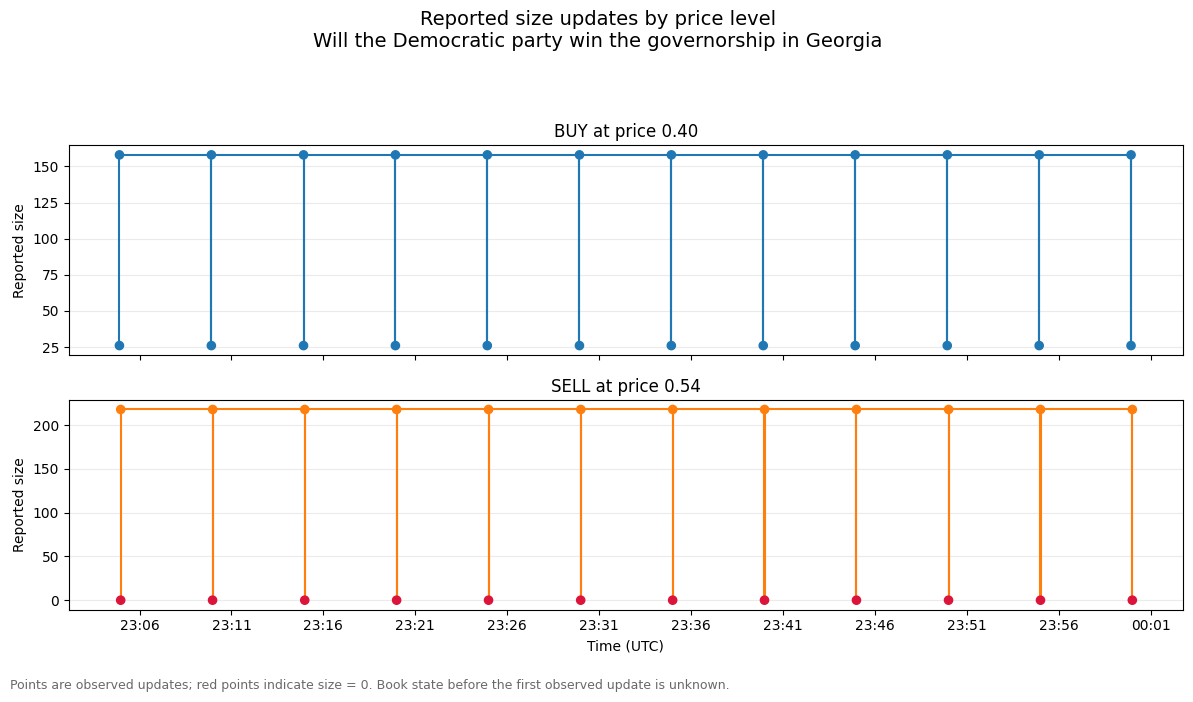

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd

market_id = "GOVPARTYGA-26-D"

# Prepare this market's observed updates
market_example = joined_df.loc[
    joined_df["asset_id"] == market_id
].copy()

market_example["_row_order"] = range(len(market_example))
market_example["orderbook_time"] = pd.to_datetime(
    market_example["ts_ms"], unit="ms", utc=True
)
market_example["price_num"] = pd.to_numeric(
    market_example["price"], errors="coerce"
)
market_example["size_num"] = pd.to_numeric(
    market_example["size"], errors="coerce"
)
market_example = market_example.sort_values(
    ["ts_ms", "_row_order"]
)

# Plot the two price levels we inspected
levels_to_plot = [
    ("BUY", 0.40, "tab:blue"),
    ("SELL", 0.54, "tab:orange"),
]

fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(12, 7),
    sharex=True,
)

for ax, (side, price, color) in zip(axes, levels_to_plot):
    level = market_example.loc[
        (market_example["side"] == side)
        & np.isclose(market_example["price_num"], price)
    ].sort_values(["ts_ms", "_row_order"])

    if level.empty:
        ax.set_visible(False)
        continue

    # The step line carries each reported quantity forward until the next update.
    ax.step(
        level["orderbook_time"],
        level["size_num"],
        where="post",
        color=color,
        linewidth=1.5,
    )

    # Mark the actual recorded updates; highlight zero-size updates in red.
    point_colors = [
        "crimson" if size == 0 else color
        for size in level["size_num"]
    ]
    ax.scatter(
        level["orderbook_time"],
        level["size_num"],
        c=point_colors,
        s=35,
        zorder=3,
    )

    ax.set_title(f"{side} at price {price:.2f}")
    ax.set_ylabel("Reported size")
    ax.grid(axis="y", alpha=0.25)

market_title = (
    market_example["market_title"].dropna().iloc[0]
    if "market_title" in market_example.columns
    and market_example["market_title"].notna().any()
    else market_id
)

fig.suptitle(
    f"Reported size updates by price level\n{market_title}",
    fontsize=14,
)
axes[-1].set_xlabel("Time (UTC)")
axes[-1].xaxis.set_major_locator(
    mdates.MinuteLocator(interval=5, tz=mdates.UTC)
)
axes[-1].xaxis.set_major_formatter(
    mdates.DateFormatter("%H:%M", tz=mdates.UTC)
)

fig.text(
    0.01,
    0.01,
    "Points are observed updates; red points indicate size = 0. "
    "Book state before the first observed update is unknown.",
    fontsize=9,
    color="dimgray",
)

plt.tight_layout(rect=[0, 0.04, 1, 0.92])
plt.show()

In [ ]:
sports_df = eda_df.loc[
    eda_df["event_category"] == "Sports"
].copy()

sports_market_summary = (
    sports_df.groupby(
        ["asset_id", "market_title", "event_slug", "event_title"],
        dropna=False,
    )
    .agg(
        updates=("ts_ms", "size"),
        buy_updates=("side", lambda s: (s == "BUY").sum()),
        sell_updates=("side", lambda s: (s == "SELL").sum()),
        first_update=("orderbook_time", "min"),
        last_update=("orderbook_time", "max"),
    )
    .sort_values("updates", ascending=False)
)

display(sports_market_summary.head(15))

,,,,updates,buy_updates,sell_updates,first_update,last_update
asset_id,market_title,event_slug,event_title,,,,,
KXWNBATEAMTOTAL-26OCT09ATLNY-NY77,New York over 76.5 points scored,KXWNBATEAMTOTAL-26OCT09ATLNY,Atlanta vs New York: Team Total,31578,24013,7565,2026-10-09 23:00:02.341000+00:00,2026-10-09 23:59:59.591000+00:00
KXWNBASPREAD-26OCT09ATLNY-NY4,New York wins the game by over 3.5 points,KXWNBASPREAD-26OCT09ATLNY,Atlanta vs New York: Spread,17390,8195,9195,2026-10-09 23:00:04.466000+00:00,2026-10-09 23:59:56.206000+00:00
KXLIGAEXPSPREAD-26OCT09TAPCLU-CLU3,Club Atletico La Paz wins by more than 2.5 goals?,KXLIGAEXPSPREAD-26OCT09TAPCLU,Tapatio vs Club Atletico La Paz: Spread,17220,6523,10697,2026-10-09 23:00:00.268000+00:00,2026-10-09 23:58:57.350000+00:00
KXLOLGAME-26OCT091700DSGFUE-FUE,Fuego wins,KXLOLGAME-26OCT091700DSGFUE,Disguised vs. Fuego,16988,6997,9991,2026-10-09 23:00:00.328000+00:00,2026-10-09 23:59:59.827000+00:00
KXWNBATEAMTOTAL-26OCT09ATLNY-ATL79,Atlanta over 78.5 points scored,KXWNBATEAMTOTAL-26OCT09ATLNY,Atlanta vs New York: Team Total,15655,8647,7008,2026-10-09 23:00:07.834000+00:00,2026-10-09 23:59:59.620000+00:00
KXLIGAEXPSPREAD-26OCT09TAPCLU-TAP3,Tapatio wins by more than 2.5 goals?,KXLIGAEXPSPREAD-26OCT09TAPCLU,Tapatio vs Club Atletico La Paz: Spread,13316,839,12477,2026-10-09 23:00:00.259000+00:00,2026-10-09 23:56:11.761000+00:00
KXPGATOUR-BAC26-RCAS,Baycurrent Classic: Ricky Castillo wins,KXPGATOUR-BAC26,Baycurrent Classic Winner,9168,3146,6022,2026-10-09 23:00:02.066000+00:00,2026-10-09 23:59:59.814000+00:00
KXITFWDOUBLES-26OCT09JURSOFAILMEA-AILMEA,Ailin Larraya Guidi / Meabe wins,KXITFWDOUBLES-26OCT09JURSOFAILMEA,Jurado / Sofia Madrid Rocca vs Ailin Larraya Guidi / Meabe,8927,8918,9,2026-10-09 23:00:00.160000+00:00,2026-10-09 23:59:07.833000+00:00
KXWNBA2HWINNER-26OCT09GSLV-GS,Golden State wins the 2nd half?,KXWNBA2HWINNER-26OCT09GSLV,Golden State vs Las Vegas: Second Half Winner,8664,8625,39,2026-10-09 23:10:26.577000+00:00,2026-10-09 23:59:59.372000+00:00


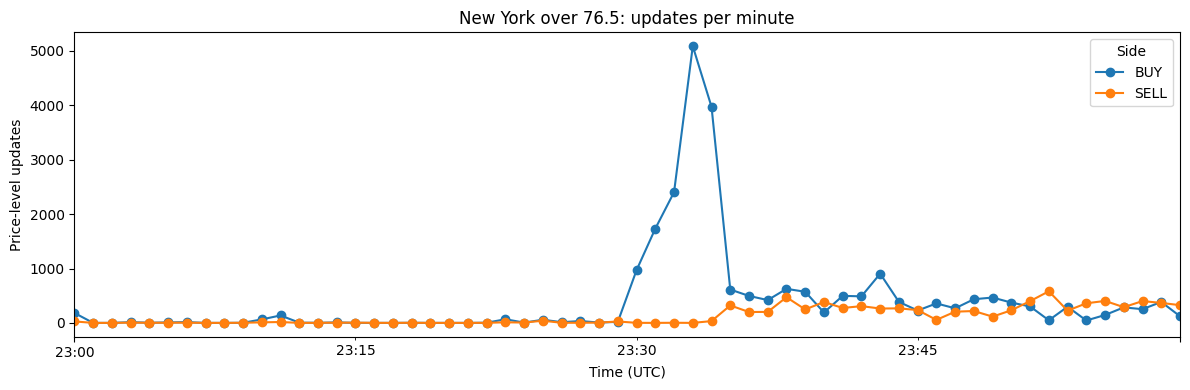

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

market_id = "KXWNBATEAMTOTAL-26OCT09ATLNY-NY77"

market_df = eda_df.loc[
    eda_df["asset_id"] == market_id
].copy()

market_df["minute"] = market_df["orderbook_time"].dt.floor("min")

minute_side_counts = (
    market_df.groupby(["minute", "side"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=["BUY", "SELL"], fill_value=0)
)

minute_range = pd.date_range(
    start=market_df["minute"].min(),
    end=market_df["minute"].max(),
    freq="min",
)
minute_side_counts = minute_side_counts.reindex(minute_range, fill_value=0)

ax = minute_side_counts.plot(
    figsize=(12, 4),
    marker="o",
    title="New York over 76.5: updates per minute",
    xlabel="Time (UTC)",
    ylabel="Price-level updates",
)

ax.legend(title="Side")
plt.tight_layout()
plt.show()

In [ ]:
category = "Economics"
spike_minute = pd.Timestamp("2026-10-09 23:20:00", tz="UTC")

spike = eda_df.loc[
    (eda_df["event_category"] == category)
    & (eda_df["orderbook_time"].dt.floor("min") == spike_minute)
].copy()

print(f"Total updates in {category} at {spike_minute}: {len(spike):,}")

event_counts = (
    spike.groupby(["event_slug", "event_title"], dropna=False)
    .size()
    .rename("updates")
    .sort_values(ascending=False)
    .to_frame()
)

market_counts = (
    spike.groupby(
        ["event_title", "asset_id", "market_title"],
        dropna=False,
    )
    .size()
    .rename("updates")
    .sort_values(ascending=False)
    .to_frame()
)

print("Events contributing the most updates:")
display(event_counts.head(10))

print("Markets contributing the most updates:")
display(market_counts.head(10))

Total updates in Economics at 2026-10-09 23:20:00+00:00: 2,471
Events contributing the most updates:


,,updates
event_slug,event_title,
KXAAAGASDCO-26OCT10,Colorado gas prices tomorrow,2201
KXU3MAX-27,How high will unemployment get in 2026?,39
KXAAAGASDAZ-26OCT10,Arizona gas prices tomorrow,24
KXAAAGASDSC-26OCT10,South Carolina gas prices tomorrow,22
KXNFPROD-27MAR04,U.S. nonfarm productivity YoY above 3% in any 2026 quarter?,21
KX30YMORTW-26OCT15,30-year mortgage rate this week,20
KXAAAGASDIN-26OCT10,Indiana gas prices tomorrow,18
KXAAAGASDTN-26OCT10,Tennessee gas prices tomorrow,18
KXAAAGASDWA-26OCT10,Washington gas prices tomorrow,16


Markets contributing the most updates:


,,,updates
event_title,asset_id,market_title,
Colorado gas prices tomorrow,KXAAAGASDCO-26OCT10-4.2300,Will average **gas prices** be above $4.2300?,2201
How high will unemployment get in 2026?,KXU3MAX-27-6,How high will unemployment get before 2027?,39
Arizona gas prices tomorrow,KXAAAGASDAZ-26OCT10-4.7350,Will average **gas prices** be above $4.7350?,23
South Carolina gas prices tomorrow,KXAAAGASDSC-26OCT10-4.0300,Will average **gas prices** be above $4.0300?,22
U.S. nonfarm productivity YoY above 3% in any 2026 quarter?,KXNFPROD-27MAR04-T3,Will U.S. nonfarm productivity YoY in any quarter for 2026 be above 3%?,21
Tennessee gas prices tomorrow,KXAAAGASDTN-26OCT10-3.9650,Will average **gas prices** be above $3.9650?,18
30-year mortgage rate this week,KX30YMORTW-26OCT15-T7.40,"Will the average U.S. 30-year fixed-rate mortgage rate for Oct 15, 2026 be above 7.40%?",15
Minnesota gas prices tomorrow,KXAAAGASDMN-26OCT10-4.2900,Will average **gas prices** be above $4.2900?,15
Virginia gas prices tomorrow,KXAAAGASDVA-26OCT10-4.2000,Will average **gas prices** be above $4.2000?,13


In [ ]:
market_id = "KXAAAGASDCO-26OCT10-4.2300"

start = pd.Timestamp("2026-10-09 23:18:00", tz="UTC")
end = pd.Timestamp("2026-10-09 23:23:00", tz="UTC")

gas_window = eda_df.loc[
    (eda_df["asset_id"] == market_id)
    & (eda_df["orderbook_time"] >= start)
    & (eda_df["orderbook_time"] < end)
].copy()

gas_window["minute"] = gas_window["orderbook_time"].dt.floor("min")

print(f"Updates in this market from 23:18–23:22 UTC: {len(gas_window):,}")

print("Updates by minute and side:")
display(
    gas_window.groupby(["minute", "side"])
    .size()
    .unstack(fill_value=0)
)

print("Most frequently updated price levels:")
display(
    gas_window.groupby(["side", "price"])
    .agg(
        updates=("size", "size"),
        zero_size_updates=("size", lambda s: (s == 0).sum()),
    )
    .sort_values("updates", ascending=False)
    .head(10)
)

Updates in this market from 23:18–23:22 UTC: 3,576
Updates by minute and side:


side,BUY,SELL
minute,,
2026-10-09 23:18:00+00:00,16,8
2026-10-09 23:19:00+00:00,6,0
2026-10-09 23:20:00+00:00,819,1382
2026-10-09 23:21:00+00:00,469,797
2026-10-09 23:22:00+00:00,36,43


Most frequently updated price levels:


updates  zero_size_updates
side price                            
SELL 0.91      1225                326
BUY  0.86       661                331
     0.87       659                329
SELL 0.90       655                332
     0.99       345                  0
BUY  0.85        10                  1
     0.84         9                  1
     0.83         4                  1
     0.01         3                  0
SELL 0.88         2                  1

In [ ]:
market_id = "KXAAAGASDCO-26OCT10-4.2300"

gas = eda_df.loc[eda_df["asset_id"] == market_id].copy()
gas["_row_order"] = range(len(gas))
gas["size_num"] = pd.to_numeric(gas["size"], errors="coerce")
gas["price_num"] = pd.to_numeric(gas["price"], errors="coerce")

gas = gas.sort_values(["ts_ms", "_row_order"])
gas["previous_size"] = (
    gas.groupby(["side", "price_num"])["size_num"].shift()
)
gas["size_change"] = gas["size_num"] - gas["previous_size"]

start = pd.Timestamp("2026-10-09 23:20:00", tz="UTC")
end = pd.Timestamp("2026-10-09 23:22:00", tz="UTC")

burst = gas.loc[
    (gas["orderbook_time"] >= start)
    & (gas["orderbook_time"] < end)
]

display(
    burst.groupby("side").agg(
        updates=("size_num", "size"),
        quantity_increases=("size_change", lambda s: (s > 0).sum()),
        quantity_decreases=("size_change", lambda s: (s < 0).sum()),
        zero_size_updates=("size_num", lambda s: (s == 0).sum()),
    )
)

,updates,quantity_increases,quantity_decreases,zero_size_updates
side,,,,
BUY,1288,636,636,646
SELL,2179,1098,1061,644


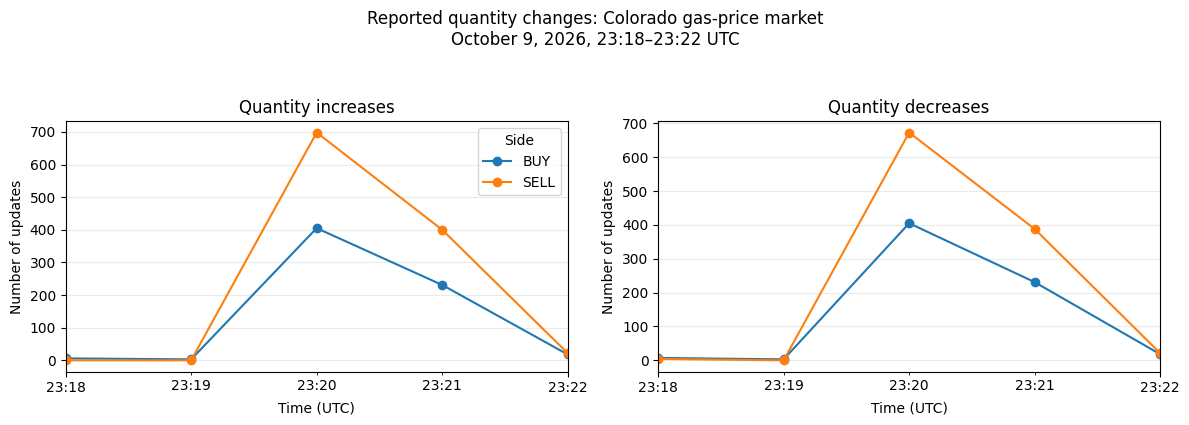

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

market_id = "KXAAAGASDCO-26OCT10-4.2300"

gas = eda_df.loc[eda_df["asset_id"] == market_id].copy()
gas["size_num"] = pd.to_numeric(gas["size"], errors="coerce")
gas["price_num"] = pd.to_numeric(gas["price"], errors="coerce")
gas["time"] = pd.to_datetime(gas["ts_ms"], unit="ms", utc=True)

gas = gas.sort_values(["time"])
gas["previous_size"] = (
    gas.groupby(["side", "price_num"])["size_num"].shift()
)
gas["size_change"] = gas["size_num"] - gas["previous_size"]

start = pd.Timestamp("2026-10-09 23:18:00", tz="UTC")
end = pd.Timestamp("2026-10-09 23:23:00", tz="UTC")

burst = gas.loc[
    (gas["time"] >= start)
    & (gas["time"] < end)
    & gas["size_change"].notna()
].copy()

burst["minute"] = burst["time"].dt.floor("min")

# Count quantity increases and decreases by minute and side
changes = (
    burst.assign(
        increase=burst["size_change"] > 0,
        decrease=burst["size_change"] < 0,
    )
    .groupby(["minute", "side"])[["increase", "decrease"]]
    .sum()
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)

for ax, change_type, title in [
    (axes[0], "increase", "Quantity increases"),
    (axes[1], "decrease", "Quantity decreases"),
]:
    plot_data = (
        changes[change_type]
        .unstack("side", fill_value=0)
        .reindex(columns=["BUY", "SELL"], fill_value=0)
    )
    plot_data.plot(ax=ax, marker="o")
    ax.set_title(title)
    ax.set_xlabel("Time (UTC)")
    ax.set_ylabel("Number of updates")
    ax.grid(axis="y", alpha=0.25)

fig.suptitle(
    "Reported quantity changes: Colorado gas-price market\n"
    "October 9, 2026, 23:18–23:22 UTC",
    y=1.05,
)
axes[0].legend(title="Side")
axes[1].get_legend().remove()

plt.tight_layout()
plt.show()

In [ ]:
market_id = "KXWNBATEAMTOTAL-26OCT09ATLNY-NY77"  # New York over 76.5 points

market_rows = eda_df.loc[eda_df["asset_id"] == market_id].copy()

print("Rows:", len(market_rows))
print("Market:", market_rows["market_title"].iloc[0])

Rows: 31578
Market: New York over 76.5 points scored


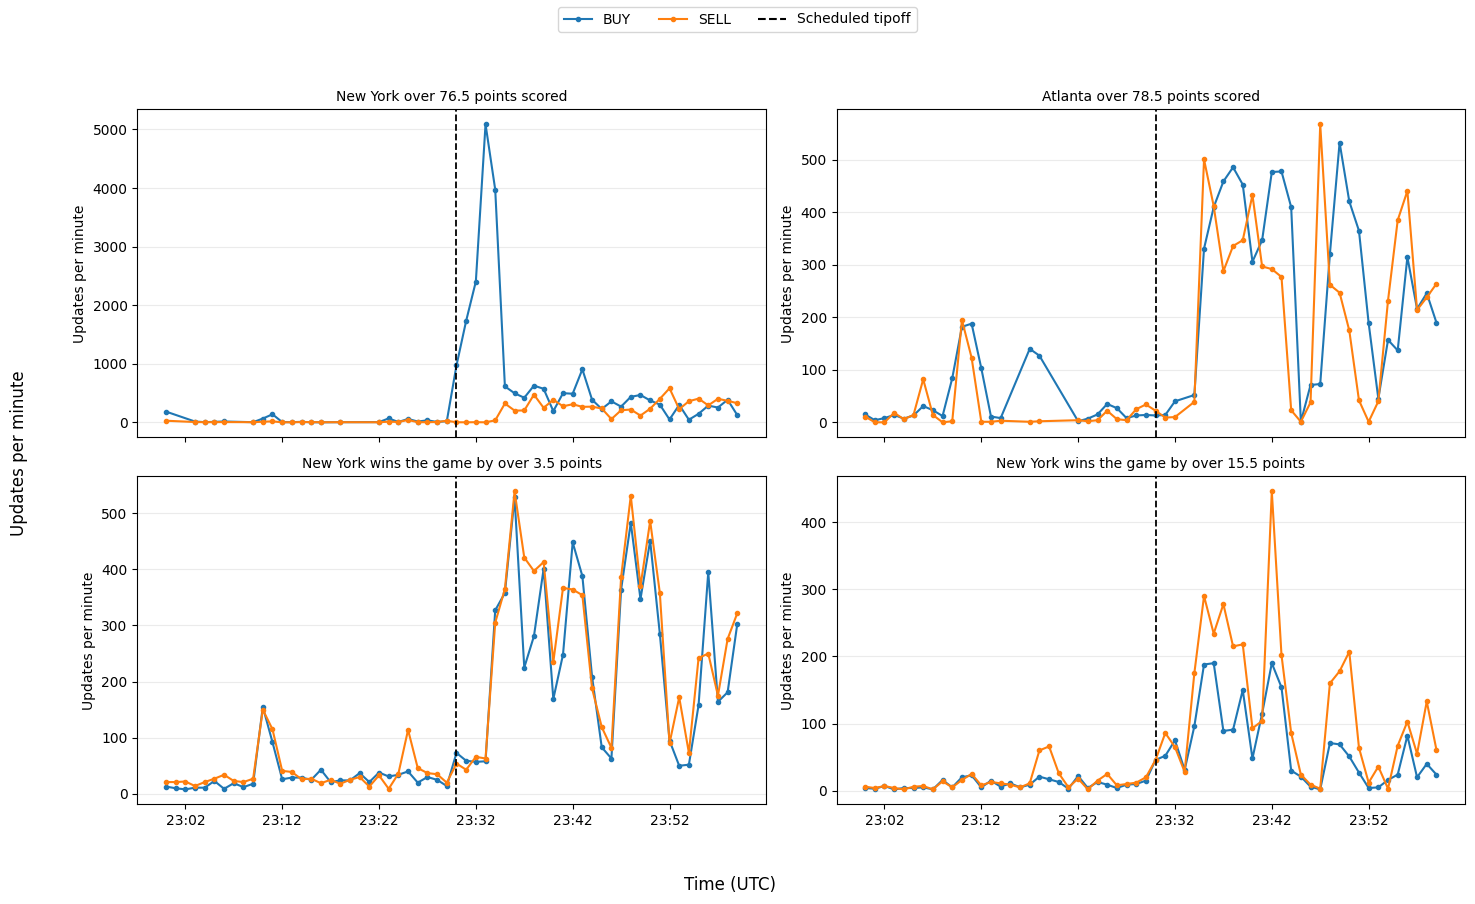

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

# Four markets from Atlanta vs. New York
market_ids = [
    "KXWNBATEAMTOTAL-26OCT09ATLNY-NY77",  # New York over 76.5 points
    "KXWNBATEAMTOTAL-26OCT09ATLNY-ATL79", # Atlanta over 78.5 points
    "KXWNBASPREAD-26OCT09ATLNY-NY4",      # New York by over 3.5 points
    "KXWNBASPREAD-26OCT09ATLNY-NY16",     # New York by over 15.5 points
]

tipoff = pd.Timestamp("2026-10-09 23:30:00", tz="UTC")
fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharex=True)
axes = axes.flatten()

for ax, market_id in zip(axes, market_ids):
    rows = eda_df.loc[eda_df["asset_id"] == market_id].copy()

    if rows.empty:
        ax.set_title(f"No rows found for {market_id}")
        ax.axis("off")
        continue

    rows["orderbook_time"] = pd.to_datetime(
        rows["ts_ms"], unit="ms", utc=True
    )
    rows["minute"] = rows["orderbook_time"].dt.floor("min")

    counts = (
        rows.groupby(["minute", "side"])
        .size()
        .unstack(fill_value=0)
        .reindex(columns=["BUY", "SELL"], fill_value=0)
    )

    title = rows["market_title"].dropna()
    title = title.iloc[0] if not title.empty else market_id

    for side, color in [("BUY", "tab:blue"), ("SELL", "tab:orange")]:
        ax.plot(
            counts.index,
            counts[side],
            marker="o",
            markersize=3,
            linewidth=1.5,
            label=side,
            color=color,
        )

    ax.axvline(
        tipoff,
        color="black",
        linestyle="--",
        linewidth=1.3,
    )
    ax.set_title(title, fontsize=10)
    ax.set_ylabel("Updates per minute")
    ax.grid(axis="y", alpha=0.25)
    ax.xaxis.set_major_locator(mdates.MinuteLocator(interval=10, tz=mdates.UTC))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=mdates.UTC))

# One shared legend for all four panels
handles, labels = axes[0].get_legend_handles_labels()
handles.append(plt.Line2D([0], [0], color="black", linestyle="--"))
labels.append("Scheduled tipoff")
fig.legend(handles, labels, loc="upper center", ncol=3, title="")
fig.supxlabel("Time (UTC)")
fig.supylabel("Updates per minute")
plt.tight_layout(rect=[0.03, 0.03, 1, 0.92])
plt.show()

In [ ]:
market_id = "KXWNBATEAMTOTAL-26OCT09ATLNY-NY77"

ny_market = eda_df.loc[eda_df["asset_id"] == market_id].copy()
ny_market["time"] = pd.to_datetime(ny_market["ts_ms"], unit="ms", utc=True)
ny_market["price_num"] = pd.to_numeric(ny_market["price"], errors="coerce")
ny_market["size_num"] = pd.to_numeric(ny_market["size"], errors="coerce")

# Order updates within each market, side, and price level.
ny_market = ny_market.sort_values(["time"])
ny_market["previous_size"] = (
    ny_market.groupby(["side", "price_num"])["size_num"].shift()
)
ny_market["size_changed"] = (
    ny_market["size_num"] != ny_market["previous_size"]
)

# Summarize BUY updates around the spike
start = pd.Timestamp("2026-10-09 23:30:00", tz="UTC")
end = pd.Timestamp("2026-10-09 23:36:00", tz="UTC")

buy_spike = ny_market.loc[
    (ny_market["side"] == "BUY")
    & (ny_market["time"] >= start)
    & (ny_market["time"] < end)
].copy()

buy_spike["minute"] = buy_spike["time"].dt.floor("min")

summary = (
    buy_spike.groupby("minute")
    .agg(
        updates=("price_num", "size"),
        distinct_prices=("price_num", "nunique"),
        quantity_changed=("size_changed", "sum"),
        zero_size_updates=("size_num", lambda s: (s == 0).sum()),
    )
)

display(summary)

,updates,distinct_prices,quantity_changed,zero_size_updates
minute,,,,
2026-10-09 23:30:00+00:00,970,21,970,441
2026-10-09 23:31:00+00:00,1733,32,1710,812
2026-10-09 23:32:00+00:00,2403,21,2377,1158
2026-10-09 23:33:00+00:00,5088,28,4960,2533
2026-10-09 23:34:00+00:00,3973,36,3858,1967
2026-10-09 23:35:00+00:00,613,45,612,164


In [ ]:
has_previous = buy_spike["previous_size"].notna()

summary = (
    buy_spike.groupby("minute")
    .agg(
        updates=("price_num", "size"),
        distinct_prices=("price_num", "nunique"),
        zero_size_updates=("size_num", lambda s: (s == 0).sum()),
    )
)

actual_changes = (
    buy_spike.loc[has_previous]
    .assign(changed=lambda x: x["size_num"] != x["previous_size"])
    .groupby("minute")["changed"]
    .sum()
    .rename("quantity_changed_after_first_observation")
)

summary = summary.join(actual_changes).fillna(
    {"quantity_changed_after_first_observation": 0}
).astype({"quantity_changed_after_first_observation": "int64"})

display(summary)

,updates,distinct_prices,zero_size_updates,quantity_changed_after_first_observation
minute,,,,
2026-10-09 23:30:00+00:00,970,21,441,966
2026-10-09 23:31:00+00:00,1733,32,812,1702
2026-10-09 23:32:00+00:00,2403,21,1158,2377
2026-10-09 23:33:00+00:00,5088,28,2533,4959
2026-10-09 23:34:00+00:00,3973,36,1967,3855
2026-10-09 23:35:00+00:00,613,45,164,609


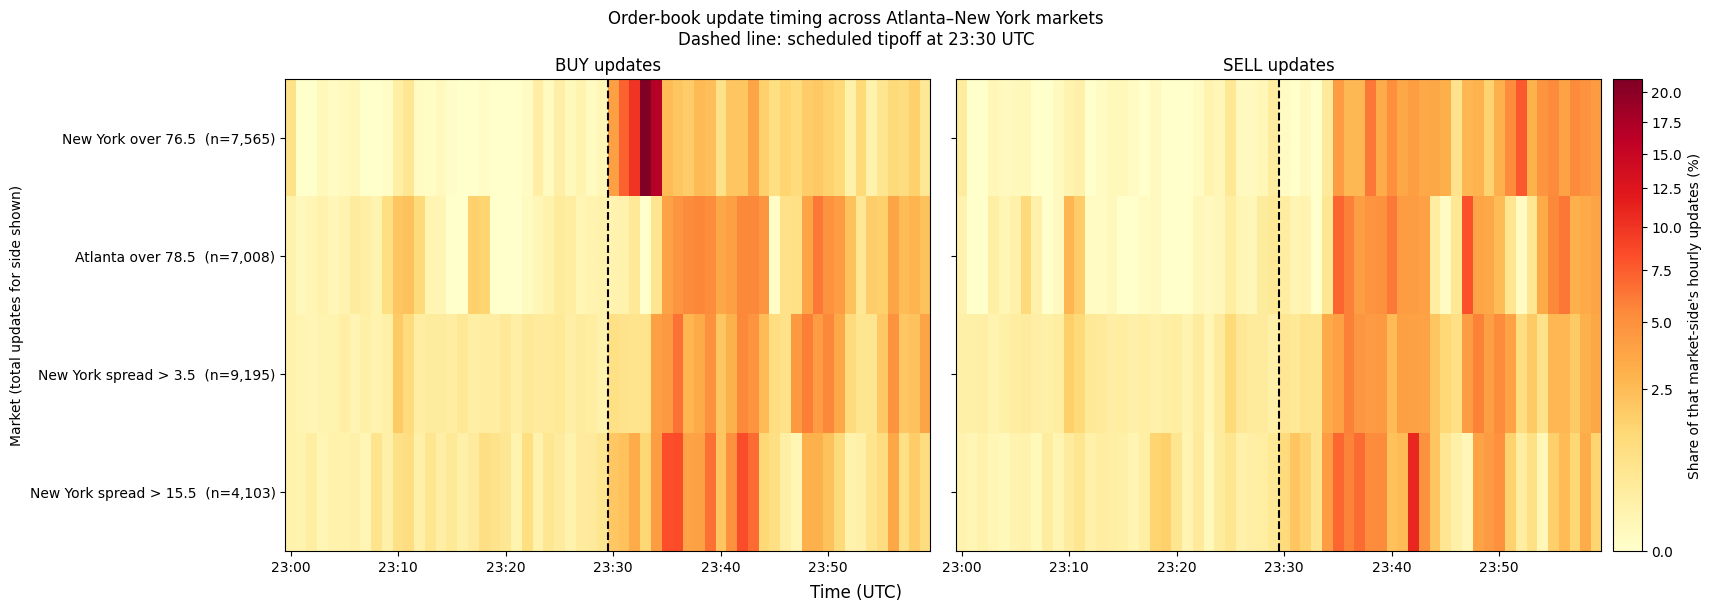

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.colors as colors
import pandas as pd
import numpy as np

market_ids = [
    "KXWNBATEAMTOTAL-26OCT09ATLNY-NY77",
    "KXWNBATEAMTOTAL-26OCT09ATLNY-ATL79",
    "KXWNBASPREAD-26OCT09ATLNY-NY4",
    "KXWNBASPREAD-26OCT09ATLNY-NY16",
]

market_labels = {
    market_ids[0]: "New York over 76.5",
    market_ids[1]: "Atlanta over 78.5",
    market_ids[2]: "New York spread > 3.5",
    market_ids[3]: "New York spread > 15.5",
}

start = pd.Timestamp("2026-10-09 23:00:00", tz="UTC")
minutes = pd.date_range(start=start, periods=60, freq="min")
end = start + pd.Timedelta(hours=1)

plot_df = eda_df.loc[eda_df["asset_id"].isin(market_ids)].copy()
plot_df["time"] = pd.to_datetime(plot_df["ts_ms"], unit="ms", utc=True)
plot_df = plot_df.loc[(plot_df["time"] >= start) & (plot_df["time"] < end)]
plot_df["minute"] = plot_df["time"].dt.floor("min")

# Build a separate percentage row and correct total for each market and side.
heatmaps = {}
row_labels = {}

for side in ["BUY", "SELL"]:
    rows = []
    labels = []

    for market_id in market_ids:
        market_side = plot_df.loc[
            (plot_df["asset_id"] == market_id)
            & (plot_df["side"] == side)
        ]

        minute_counts = (
            market_side.groupby("minute")
            .size()
            .reindex(minutes, fill_value=0)
        )

        total = int(minute_counts.sum())
        percentages = minute_counts / total * 100 if total else minute_counts.astype(float)

        rows.append(percentages.to_numpy())
        labels.append(f"{market_labels[market_id]}  (n={total:,})")

    heatmaps[side] = np.vstack(rows)
    row_labels[side] = labels

vmax = max(matrix.max() for matrix in heatmaps.values())
vmax = max(vmax, 1)

# Give the two panels and the colorbar dedicated layout space.
fig = plt.figure(figsize=(17, 6), constrained_layout=True)
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 0.045])

ax_buy = fig.add_subplot(gs[0, 0])
ax_sell = fig.add_subplot(gs[0, 1], sharey=ax_buy)
cax = fig.add_subplot(gs[0, 2])

norm = colors.PowerNorm(gamma=0.5, vmin=0, vmax=vmax)

for ax, side in [(ax_buy, "BUY"), (ax_sell, "SELL")]:
    image = ax.imshow(
        heatmaps[side],
        aspect="auto",
        interpolation="nearest",
        cmap="YlOrRd",
        norm=norm,
    )

    ax.set_title(f"{side} updates")
    ax.set_yticks(range(len(market_ids)))
    ax.set_yticklabels(row_labels[side])

    tick_positions = [0, 10, 20, 30, 40, 50]
    ax.set_xticks(tick_positions)
    ax.set_xticklabels([minutes[i].strftime("%H:%M") for i in tick_positions])

    # Dashed line at the boundary before the 23:30 minute
    ax.axvline(29.5, color="black", linestyle="--", linewidth=1.5)

ax_buy.set_ylabel("Market (total updates for side shown)")
ax_sell.tick_params(axis="y", labelleft=False)

fig.colorbar(image, cax=cax).set_label(
    "Share of that market-side's hourly updates (%)"
)

fig.suptitle(
    "Order-book update timing across Atlanta–New York markets\n"
    "Dashed line: scheduled tipoff at 23:30 UTC"
)
fig.supxlabel("Time (UTC)")

plt.show()

,asset_id,market_title,event_title,event_slug
492200,KXSWIFTWEDDING-26DEC31-ARM,Will Taylor Swift wear a wedding dress designe...,Taylor Swift: Wedding Dress,KXSWIFTWEDDING-26DEC31
481143,KXRT-OTH-70,Other Mommy Rotten Tomatoes score?,Other Mommy · Rotten Tomatoes score,KXRT-OTH
416756,KXOSCARNOMACTO-27-ANT,2027 Best Actor Oscar nominations?,Oscar nominees: Best Actor,KXOSCARNOMACTO-27
471146,KXROGANGUEST-27JAN01-VR,Will Vivek Ramaswamy go on the Joe Rogan Exper...,The Joe Rogan Experience: Guests in 2026,KXROGANGUEST-27JAN01


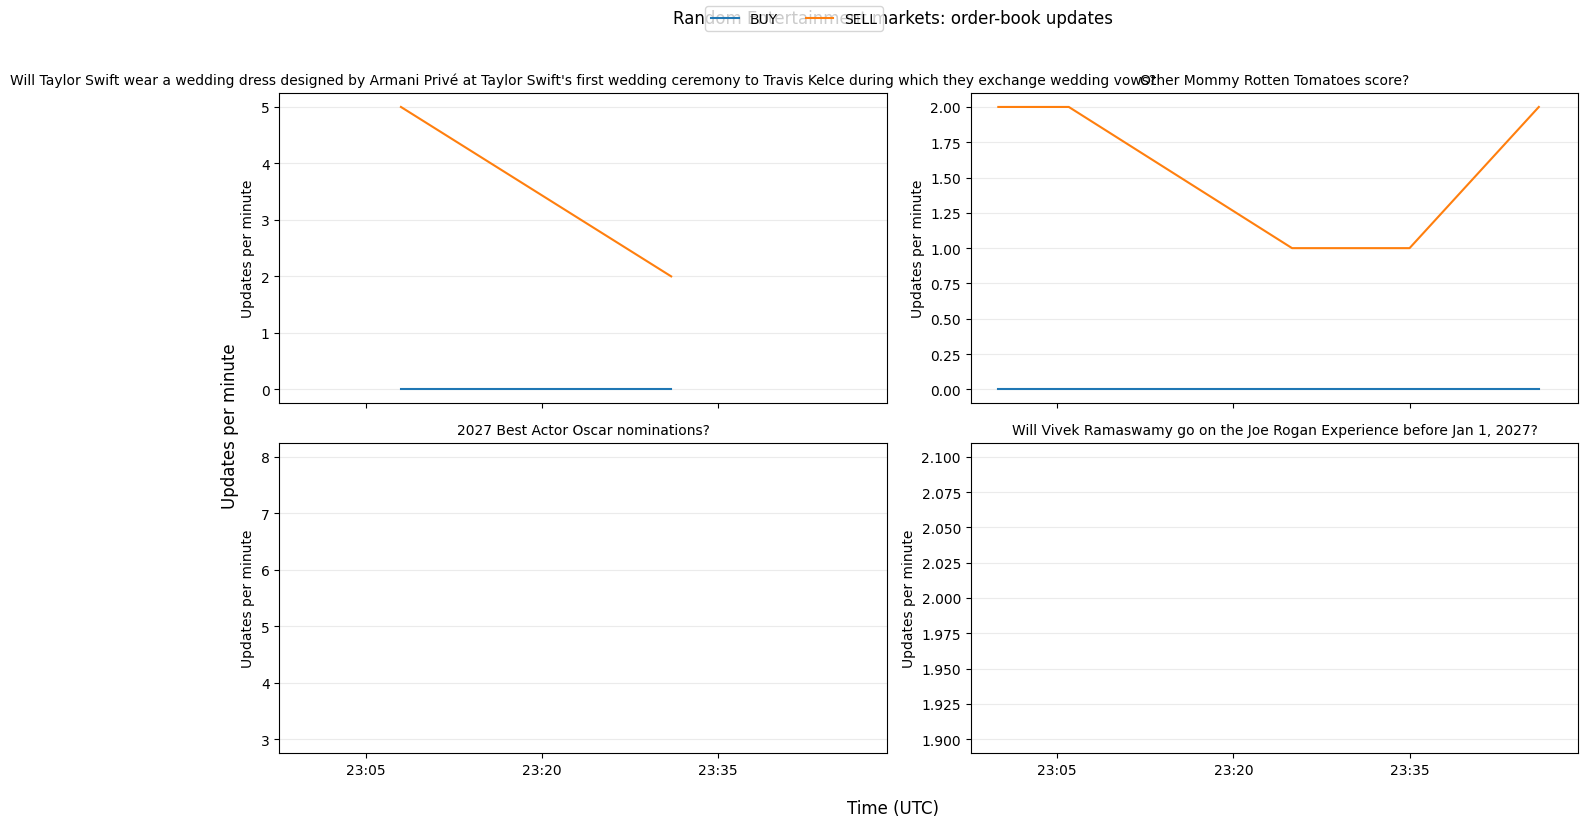

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

# Keep only rows matched to Entertainment events
entertainment = eda_df.loc[
    eda_df["event_category"].eq("Entertainment")
].copy()

# Pick four distinct markets at random
market_info = (
    entertainment[
        ["asset_id", "market_title", "event_title", "event_slug"]
    ]
    .drop_duplicates("asset_id")
)

n_markets = min(4, len(market_info))
random_markets = market_info.sample(n=n_markets, random_state=42)

display(random_markets)

# Prepare timestamps and minute bins
entertainment["orderbook_time"] = pd.to_datetime(
    entertainment["ts_ms"], unit="ms", utc=True
)
entertainment["minute"] = entertainment["orderbook_time"].dt.floor("min")

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
axes = axes.flatten()

for ax, (_, market) in zip(axes, random_markets.iterrows()):
    rows = entertainment.loc[
        entertainment["asset_id"] == market["asset_id"]
    ]

    counts = (
        rows.groupby(["minute", "side"])
        .size()
        .unstack(fill_value=0)
        .reindex(columns=["BUY", "SELL"], fill_value=0)
    )

    for side, color in [("BUY", "tab:blue"), ("SELL", "tab:orange")]:
        ax.plot(counts.index, counts[side], label=side, color=color)

    ax.set_title(market["market_title"], fontsize=10)
    ax.set_ylabel("Updates per minute")
    ax.grid(axis="y", alpha=0.25)
    ax.xaxis.set_major_locator(mdates.MinuteLocator(interval=15, tz=mdates.UTC))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=mdates.UTC))

# Hide any unused panels if fewer than four markets were available
for ax in axes[n_markets:]:
    ax.set_visible(False)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2)
fig.suptitle("Random Entertainment markets: order-book updates", y=1.02)
fig.supxlabel("Time (UTC)")
fig.supylabel("Updates per minute")

plt.tight_layout()
plt.show()